## Tidy version of ML code

for mutli model comparison

In [1]:
import iris
import iris.coord_categorisation as cat
import iris.analysis as ia
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import cf_units
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

from sklearn.preprocessing import PowerTransformer, StandardScaler
from sklearn.cluster import KMeans
from scipy.spatial.distance import cdist
from sklearn.metrics import pairwise_distances




In [ ]:
TARGET_TIME_UNITS = cf_units.Unit(
        'days since 2015-01-01 00:00:00', 
        calendar=cf_units.CALENDAR_GREGORIAN
    )

def normalize_time_to_target_units(cube, target_units=TARGET_TIME_UNITS):
    """Convert cube's 'time' points (and bounds) to target units/calendar and sort."""
    if not cube.coords('time'):
        raise ValueError("Cube has no 'time' coordinate.")
    time = cube.coord('time')

    # Convert numeric points -> datetimes via the current units/calendar
    current_units = time.units
    datetimes = current_units.num2date(time.points)

    # Re-encode datetimes -> numeric points in target units
    new_points = target_units.date2num(datetimes)
    time.units = target_units
    time.points = new_points

    # Preserve bounds if present
    if time.has_bounds():
        lower = current_units.num2date(time.bounds[:, 0])
        upper = current_units.num2date(time.bounds[:, 1])
        new_bounds = np.column_stack([
            target_units.date2num(lower),
            target_units.date2num(upper)
        ])
        time.bounds = new_bounds

    # Ensure monotonic order along time
    order = np.argsort(time.points)
    if not np.all(order == np.arange(len(order))):
        cube = cube[order]

    return cube

def concat_time_cubes(cubes):
    """Equalise attributes, unify time units, sort by first time, and concatenate."""
    # Harmonise non-critical attributes (title, history, etc.)
    iris.util.equalise_attributes(cubes)

    # Unify time units (safe even after explicit normalization)
    iris.util.unify_time_units(cubes)

    # Sort cubes by their first time point to be safe
    def first_time_dt(c):
        t = c.coord('time')
        return t.units.num2date(t.points[0])
    cubes.sort(key=first_time_dt)

    # Concatenate into a single continuous cube
    combined = iris.cube.CubeList(cubes).concatenate_cube()
    return combined

def check_daily_continuity(cube):
    """Optional: simple continuity check for daily cadence."""
    t = cube.coord('time')
    # Convert to datetime64 for delta checks
    times = np.array(t.units.num2date(t.points), dtype='datetime64[ns]')
    diffs = np.diff(times)
    unique_steps = np.unique(diffs)
    strictly_increasing = np.all(diffs > np.timedelta64(0, 'D'))
    daily = np.all(unique_steps == np.timedelta64(1, 'D'))
    return strictly_increasing, daily, unique_steps

def read_clean_data(model_path, restan = False):
    #------------read in obs data ----------------------------
    DATADIR = '/observational_data' #new VDI
    ERA5_precip = iris.load_cube(f'{DATADIR}/amazon_lowlandprecip_ERA5.nc')
    ERA5_temp = iris.load_cube(f'{DATADIR}/amazon_lowlandtemp_ERA5.nc')
    phosphorous = iris.load_cube(f'{DATADIR}/amazon_lowlandP.nc')

    phos_regrid = phosphorous.regrid(ERA5_temp, iris.analysis.Linear())

    # save lat and lon coords of cube
    lats = ERA5_temp.coord('latitude').points
    lons = ERA5_temp.coord('longitude').points
    #make a meshgrid
    lons, lats = np.meshgrid(lons, lats)

    df_era = pd.DataFrame({
        'Temperature': ERA5_temp.data.flatten(),
        'Precipitation': ERA5_precip.data.flatten(),
        'Phosphorous': phos_regrid.data.flatten(),
        'Latitude': lats.flatten(),
        'Longitude': lons.flatten()})
    
    df_era.dropna(inplace=True)
    
    ISIMIP_DATADIR = '/ISIMIP_data'
    
    # ---- Load historic and projected cubes individually----
    ISI_driv_precip_2001_2010 = iris.load_cube(f'{ISIMIP_DATADIR}/{model_path}_w5e5_historical_prAdjust_global_daily_2001_2010.nc')
    ISI_driv_precip_2011_2014 = iris.load_cube(f'{ISIMIP_DATADIR}/{model_path}_w5e5_historical_prAdjust_global_daily_2011_2014.nc')
    ISI_driv_temp_2001_2010 = iris.load_cube(f'{ISIMIP_DATADIR}/{model_path}_w5e5_historical_tasAdjust_global_daily_2001_2010.nc')
    ISI_driv_temp_2011_2014 = iris.load_cube(f'{ISIMIP_DATADIR}/{model_path}_w5e5_historical_tasAdjust_global_daily_2011_2014.nc')
    ISI_precip_2081_2090 = iris.load_cube(f'{ISIMIP_DATADIR}/{model_path}_w5e5_ssp370_prAdjust_global_daily_2081_2090.nc')
    ISI_precip_2091_2100 = iris.load_cube(f'{ISIMIP_DATADIR}/{model_path}_w5e5_ssp370_prAdjust_global_daily_2091_2100.nc')
    ISI_temp_2081_2090 = iris.load_cube(f'{ISIMIP_DATADIR}/{model_path}_w5e5_ssp370_tasAdjust_global_daily_2081_2090.nc')
    ISI_temp_2091_2100 = iris.load_cube(f'{ISIMIP_DATADIR}/{model_path}_w5e5_ssp370_tasAdjust_global_daily_2091_2100.nc')



    # ---- Normalize each cube's time to the target units ----
    precip_driv_cubes = [
        normalize_time_to_target_units(ISI_driv_precip_2001_2010),
        normalize_time_to_target_units(ISI_driv_precip_2011_2014),
    ]
    temp_driv_cubes = [
        normalize_time_to_target_units(ISI_driv_temp_2001_2010),
        normalize_time_to_target_units(ISI_driv_temp_2011_2014),
    ]
    precip_proj_cubes = [
        normalize_time_to_target_units(ISI_precip_2081_2090),
        normalize_time_to_target_units(ISI_precip_2091_2100),
    ]
    temp_proj_cubes = [
        normalize_time_to_target_units(ISI_temp_2081_2090),
        normalize_time_to_target_units(ISI_temp_2091_2100),
    ]

    # ---- Concatenate into continuous series ----
    ISI_driv_precip = concat_time_cubes(precip_driv_cubes)
    ISI_driv_temp   = concat_time_cubes(temp_driv_cubes)
    ISI_precip_proj = concat_time_cubes(precip_proj_cubes)
    ISI_temp_proj   = concat_time_cubes(temp_proj_cubes)


    # if data doesnt have 'year' auxiliary coordinate derived from 'time'
    for cube in [ISI_driv_precip, ISI_driv_temp, ISI_precip_proj, ISI_temp_proj]:
        if not cube.coords('year'):
            cat.add_year(cube, 'time', name='year') 


    #Aggregate by the 'year' category using mean
    annual_mean_precip_driv = ISI_driv_precip.aggregated_by('year', ia.MEAN)
    annual_mean_temp_driv = ISI_driv_temp.aggregated_by('year', ia.MEAN)
    annual_mean_precip_proj = ISI_precip_proj.aggregated_by('year', ia.MEAN)
    annual_mean_temp_proj = ISI_temp_proj.aggregated_by('year', ia.MEAN)

    #now average over the yearly data to get a climatology
    ISI_driv_precip_clim = annual_mean_precip_driv.collapsed('year', ia.MEAN)
    ISI_driv_temp_clim = annual_mean_temp_driv.collapsed('year', ia.MEAN)
    ISI_precip_clim_proj = annual_mean_precip_proj.collapsed('year', ia.MEAN)
    ISI_temp_clim_proj = annual_mean_temp_proj.collapsed('year', ia.MEAN)

    #convert temperature from K to C
    ISI_driv_temp_clim.data = ISI_driv_temp_clim.data - 273.15
    ISI_temp_clim_proj.data = ISI_temp_clim_proj.data - 273.15

    #convert precipitation from kg m-2 s-1 to mm/year
    ISI_driv_precip_clim.data = ISI_driv_precip_clim.data * 86400 * 365
    ISI_precip_clim_proj.data = ISI_precip_clim_proj.data * 86400 * 365
    

    #regrid to ERA5 grid
    ISI_driv_precip_regrid = ISI_driv_precip_clim.regrid(ERA5_precip, iris.analysis.Linear())
    ISI_driv_temp_regrid = ISI_driv_temp_clim.regrid(ERA5_temp, iris.analysis.Linear())
    ISI_precip_regrid_proj = ISI_precip_clim_proj.regrid(ERA5_precip, iris.analysis.Linear())
    ISI_temp_regrid_proj = ISI_temp_clim_proj.regrid(ERA5_temp, iris.analysis.Linear())
 
    mask = (ERA5_temp.data.mask) + (np.isnan(ERA5_temp.data)) + (np.abs(ERA5_temp.data) >= 1e10)

    #where mask is true set ISI_temp_regrid.data to nan
    ISI_driv_temp_regrid.data = np.where(mask, np.nan, ISI_driv_temp_regrid.data)
    ISI_temp_regrid_proj.data = np.where(mask, np.nan, ISI_temp_regrid_proj.data)   
    ISI_precip_regrid_proj.data = np.where(mask, np.nan, ISI_precip_regrid_proj.data)
    ISI_driv_precip_regrid.data = np.where(mask, np.nan, ISI_driv_precip_regrid.data)

    #make pandasdataframes of the regridded ISIMIP data
    df = pd.DataFrame({
        'Temperature': ISI_driv_temp_regrid.data.flatten(),
        'Precipitation': ISI_driv_precip_regrid.data.flatten(),
        'Phosphorous': phos_regrid.data.flatten(),
        'Latitude': lats.flatten(),
        'Longitude': lons.flatten()})

    # Drop rows with NaN values
    df.dropna(inplace=True)

    df_proj = pd.DataFrame({
        'Temperature': ISI_temp_regrid_proj.data.flatten(),
        'Precipitation': ISI_precip_regrid_proj.data.flatten(),
        'Phosphorous': phos_regrid.data.flatten(),
        'Latitude': lats.flatten(),
        'Longitude': lons.flatten()})


    # Drop rows with NaN values
    df_proj.dropna(inplace=True)

    #transform temp, precip and phosphorous data
    pt = PowerTransformer(method='yeo-johnson')
    scaler = StandardScaler()

    df_era_trans = pt.fit_transform(df_era[['Temperature', 'Precipitation', 'Phosphorous']])
    df_era_trans = scaler.fit_transform(df_era_trans)
    df_era_trans = pd.DataFrame(df_era_trans, columns=['Temperature', 'Precipitation', 'Phosphorous'])
    df_era_trans['Latitude'] = df_era['Latitude'].values
    df_era_trans['Longitude'] = df_era['Longitude'].values


    df_trans = pt.fit_transform(df[['Temperature', 'Precipitation', 'Phosphorous']])
    df_trans = scaler.fit_transform(df_trans)
    df_trans = pd.DataFrame(df_trans, columns=['Temperature', 'Precipitation', 'Phosphorous'])
    df_trans['Latitude'] = df['Latitude'].values 
    df_trans['Longitude'] = df['Longitude'].values

    #note here choose whether standardise data using fit_trans (new standardisation) or standardise in line with historic data
    df_proj_trans = pt.transform(df_proj[['Temperature', 'Precipitation', 'Phosphorous']])
    if restan == True:
        df_proj_trans = scaler.fit_transform(df_proj_trans)
    else:
        df_proj_trans = scaler.transform(df_proj_trans)
    df_proj_trans = pd.DataFrame(df_proj_trans, columns=['Temperature', 'Precipitation', 'Phosphorous'])
    df_proj_trans['Latitude'] = df_proj['Latitude'].values
    df_proj_trans['Longitude'] = df_proj['Longitude'].values
    

    return df, df_trans, df_proj, df_proj_trans, df_era, df_era_trans

def plot_data(df, df_proj, transformed=False):
    
    # Plot histograms for driving (top row) and projected (bottom row) data
    # sharex_opt = 'col' if transformed is False else False
    sharex_opt = False
    fig, axes = plt.subplots(2, 3, figsize=(18, 10), sharex=sharex_opt)

    # --- Driving data (2001–2014) ---
    axes[0, 0].hist(df['Temperature'], bins=50, color='blue', alpha=0.7)
    axes[0, 0].set_title('Temperature Distribution (2001–2014)')
    axes[0, 0].set_xlabel('Temperature (°C)')
    axes[0, 0].set_ylabel('Frequency')

    axes[0, 1].hist(df['Precipitation'], bins=50, color='green', alpha=0.7)
    axes[0, 1].set_title('Precipitation Distribution (2001–2014)')
    axes[0, 1].set_xlabel('Precipitation (mm/yr)')
    axes[0, 1].set_ylabel('Frequency')

    axes[0, 2].hist(df['Phosphorous'], bins=50, color='red', alpha=0.7)
    axes[0, 2].set_title('Phosphorous Distribution (2001–2014)')
    axes[0, 2].set_xlabel('Phosphorous')
    axes[0, 2].set_ylabel('Frequency')

    # --- Projected data (2081–2100) ---
    axes[1, 0].hist(df_proj['Temperature'], bins=50, color='blue', alpha=0.7)
    axes[1, 0].set_title('Temperature Distribution (2081–2100)')
    axes[1, 0].set_xlabel('Temperature (°C)')
    axes[1, 0].set_ylabel('Frequency')

    axes[1, 1].hist(df_proj['Precipitation'], bins=50, color='green', alpha=0.7)
    axes[1, 1].set_title('Precipitation Distribution (2081–2100)')
    axes[1, 1].set_xlabel('Precipitation (mm/yr)')
    axes[1, 1].set_ylabel('Frequency')

    axes[1, 2].hist(df_proj['Phosphorous'], bins=50, color='red', alpha=0.7)
    axes[1, 2].set_title('Phosphorous Distribution (2081–2100)')
    axes[1, 2].set_xlabel('Phosphorous')
    axes[1, 2].set_ylabel('Frequency')

    if transformed == False:
        plt.suptitle('Distributions of Temperature, Precipitation, and Phosphorous', fontsize=16)
    else:
        plt.suptitle('Distributions of TRANSFORMED Temperature, Precipitation, and Phosphorous', fontsize=16)
    plt.tight_layout()
    plt.show()

def kmeans_clustering_fit(df, n):
    kmeans = KMeans(n_clusters=n, random_state=42, n_init="auto")
    kmeans.fit(df[['Temperature', 'Precipitation', 'Phosphorous']])
    kmeans_labels = kmeans.labels_
    dist_to_centroids = pairwise_distances(df[['Temperature', 'Precipitation', 'Phosphorous']], kmeans.cluster_centers_, metric='euclidean')
    return kmeans, kmeans_labels, n, dist_to_centroids

def kmeans_clustering_predict(df_fit, df_proj, n):
    kmeans = KMeans(n_clusters=n, random_state=42, n_init="auto")
    kmeans.fit(df_fit[['Temperature', 'Precipitation', 'Phosphorous']])
    kmeans_labels = kmeans.predict(df_proj[['Temperature', 'Precipitation', 'Phosphorous']])
    dist_to_centroids = pairwise_distances(df_proj[['Temperature', 'Precipitation', 'Phosphorous']], kmeans.cluster_centers_, metric='euclidean')
    return kmeans_labels, n, dist_to_centroids

def plot_clusters(df, kmeans_labels, shared_plot=True, title = "", restan = False, model = "ipsl"):
    # n = len(np.unique(kmeans_labels))
    n = 5
    cmap_alt = plt.cm.colors.ListedColormap(['darkred', 'gold', 'orangered', 'darkgreen', 'dodgerblue'])
    norm = plt.Normalize(vmin=0, vmax=n - 1)

    if model == "ipsl" and restan == False:
        cmap_alt = plt.cm.colors.ListedColormap(['darkgreen', 'dodgerblue', 'gold', 'darkred', 'orangered'])
    elif model == "ipsl" and restan == True:
        cmap_alt = plt.cm.colors.ListedColormap(['darkgreen', 'gold', 'orangered', 'dodgerblue', 'darkred'])

    elif model == "ukesm" and restan == False:
        cmap_alt = plt.cm.colors.ListedColormap(['darkgreen', 'orangered', 'gold', 'darkred', 'dodgerblue'])
    elif model == "ukesm" and restan == True:
        cmap_alt = plt.cm.colors.ListedColormap(['gold', 'orangered', 'dodgerblue', 'darkred', 'darkgreen'])

    elif model == "gfdl":
        cmap_alt = plt.cm.colors.ListedColormap(['darkgreen', 'orangered', 'gold', 'darkred', 'dodgerblue'])
    

    elif model == "mri" and restan == False:
        cmap_alt = plt.cm.colors.ListedColormap(['darkgreen', 'darkred', 'dodgerblue', 'gold', 'orangered'])
    elif model == "mri" and restan == True:
        cmap_alt = plt.cm.colors.ListedColormap(['darkgreen', 'gold', 'orangered', 'dodgerblue', 'darkred'])

    elif model == "mpi" and restan == False:
        cmap_alt = plt.cm.colors.ListedColormap(['darkgreen', 'darkred', 'orangered', 'gold', 'dodgerblue'])
    elif model == "mpi" and restan == True:
        cmap_alt = plt.cm.colors.ListedColormap(['darkgreen', 'gold', 'orangered', 'darkred', 'dodgerblue'])


    if shared_plot:
        # Layout: top row has 2 plots, bottom row is one merged colorbar axis
        fig = plt.figure(figsize=(18, 7), constrained_layout=True)
        gs = fig.add_gridspec(2, 2, height_ratios=[20, 1])

        # --- Left subplot: 3D feature space ---
        ax1 = fig.add_subplot(gs[0, 0], projection='3d')
        ax1.scatter(
            df["Temperature"],
            df["Precipitation"],
            df["Phosphorous"],
            c=kmeans_labels,
            cmap=cmap_alt,
            alpha=0.4,
            s=10,
            vmin=0, vmax=n - 1
        )
        ax1.set_xlabel('Standardized Temperature', fontsize=14)
        ax1.set_ylabel('Standardized Precipitation', fontsize=14)
        ax1.set_zlabel('Standardized Phosphorous', fontsize=14)
        ax1.tick_params(axis='both', labelsize=12)
        ax1.view_init(elev=30, azim=10)
        ax1.set_title('Feature Space Clusters', fontsize=16)

        # --- Right subplot: spatial map ---
        ax2 = fig.add_subplot(gs[0, 1], projection=ccrs.PlateCarree())
        h2 = ax2.scatter(
            df["Longitude"], df["Latitude"],
            c=kmeans_labels, cmap=cmap_alt, s=1,
            vmin=0, vmax=n - 1,
            transform=ccrs.PlateCarree()
        )
        ax2.coastlines(zorder=-1)
        ax2.add_feature(cfeature.OCEAN, zorder=-1, edgecolor='black', facecolor='grey')
        ax2.scatter(
            -60.208056, -2.594167,
            marker='x', color='black', s=65, linewidth=2,
            label="AmazonFACE Site", transform=ccrs.PlateCarree()
        )
        ax2.set_xlabel('Longitude', fontsize=14)
        ax2.set_ylabel('Latitude', fontsize=14)
        ax2.tick_params(axis='both', labelsize=12)
        ax2.set_title(f'Spatial Clusters (k={n})', fontsize=16)
        ax2.legend(loc='lower left', fontsize=12)

        # --- Bottom merged shared colorbar (using map scatter, no alpha) ---
        cax = fig.add_subplot(gs[1, :])
        cbar = fig.colorbar(
            h2, cax=cax, orientation='horizontal',
            boundaries=np.arange(n + 1) - 0.5,
            ticks=np.arange(n)
        )
        cbar.set_label('Cluster', fontsize=14)
        cbar.ax.tick_params(labelsize=12)

    else:
        # Two subplots, each with its own colorbar
        fig = plt.figure(figsize=(18, 7), constrained_layout=True)
        gs = fig.add_gridspec(1, 2)

        # --- Left subplot: 3D feature space ---
        ax1 = fig.add_subplot(gs[0, 0], projection='3d')
        h1 = ax1.scatter(
            df["Temperature"],
            df["Precipitation"],
            df["Phosphorous"],
            c=kmeans_labels,
            cmap=cmap_alt,
            alpha=0.4,
            s=10,
            vmin=0, vmax=n - 1
        )
        ax1.set_xlabel('Standardized Temperature', fontsize=14)
        ax1.set_ylabel('Standardized Precipitation', fontsize=14)
        ax1.set_zlabel('Standardized Phosphorous', fontsize=14)
        ax1.tick_params(axis='both', labelsize=12)
        ax1.view_init(elev=30, azim=10)
        ax1.set_title('Feature Space Clusters', fontsize=16)

        # --- Right subplot: spatial map ---
        ax2 = fig.add_subplot(gs[0, 1], projection=ccrs.PlateCarree())
        h2 = ax2.scatter(
            df["Longitude"], df["Latitude"],
            c=kmeans_labels, cmap=cmap_alt, s=1,
            vmin=0, vmax=n - 1,
            transform=ccrs.PlateCarree()
        )
        ax2.coastlines(zorder=-1)
        ax2.add_feature(cfeature.OCEAN, zorder=-1, edgecolor='black', facecolor='grey')
        ax2.scatter(
            -60.208056, -2.594167,
            marker='x', color='black', s=65, linewidth=2,
            label="AmazonFACE Site", transform=ccrs.PlateCarree()
        )
        ax2.set_xlabel('Longitude', fontsize=14)
        ax2.set_ylabel('Latitude', fontsize=14)
        ax2.tick_params(axis='both', labelsize=12)
        ax2.set_title(f'Spatial Clusters (k={n})', fontsize=16)
        ax2.legend(loc='lower left', fontsize=12)

        # Use map scatter (no alpha) as the colorbar mappable for both
        cbar1 = fig.colorbar(
            h2, ax=ax1, orientation='horizontal', pad=0.08,
            boundaries=np.arange(n + 1) - 0.5, ticks=np.arange(n)
        )
        cbar1.set_label('Cluster', fontsize=12)
        cbar1.ax.tick_params(labelsize=10)

        cbar2 = fig.colorbar(
            h2, ax=ax2, orientation='horizontal', pad=0.08,
            boundaries=np.arange(n + 1) - 0.5, ticks=np.arange(n)
        )
        cbar2.set_label('Cluster', fontsize=12)
        cbar2.ax.tick_params(labelsize=10)
    plt.suptitle(title, fontsize=16)
    plt.show()

def plot_feature_space(df, kmeans_labels, proj=False):
    #like above, plot feature space scatter but projected onto 2D plane of temp, precip
        n = len(np.unique(kmeans_labels))
        # Build colormap
        cmap = plt.get_cmap('Spectral', n + 1)
        colors = [cmap(i) for i in range(n + 1)]
        if n == 5:
            colors.pop(3)  # remove yellowish color
        cmap_alt = plt.cm.colors.ListedColormap(colors) 

        if proj == True:
            #reorder the colours to be 0, 2,4,1,3
            cmap_alt = plt.cm.colors.ListedColormap([colors[0], colors[2], colors[4], colors[1], colors[3]])    
        
        fig, ax = plt.subplots(figsize=(10, 7))
        h = ax.scatter(
            df["Temperature"],
            df["Precipitation"],
            c=kmeans_labels,
            cmap=cmap_alt,
            alpha=0.4,
            s=10
        )
        ax.set_xlabel('Standardized Temperature')
        ax.set_ylabel('Standardized Precipitation')
        ax.set_title('Feature Space Clusters (Temp vs Precip)')
        cbar = fig.colorbar(h, ticks=np.arange(n))
        cbar.set_label('Cluster')
        plt.show()

def plot_marg_dist(df, cluster_labels, n, proj = False):

    # Build colormap
    cmap = plt.get_cmap('Spectral', n + 1)
    colors = [cmap(i) for i in range(n + 1)]
    if n == 5:
        colors.pop(3)  # remove yellowish color

    if proj == True:
        #reorder the colours to be 0, 2,4,1,3
        colors = [colors[0], colors[2], colors[4], colors[1], colors[3]]

    fig, axes = plt.subplots(3, 1, figsize=(10, 9))
    features = ['Temperature', 'Precipitation', 'Phosphorous']

    for idx, feature in enumerate(features):
        ax = axes[idx]
        
        # Compute fixed bin edges based on the full dataset range
        feat_min = df[feature].min()
        feat_max = df[feature].max()
        bin_edges = np.linspace(feat_min, feat_max, 151)  # 100 bins of equal width

        # Plot histogram of feature data for each cluster
        for cluster in range(n):
            ax.hist(df.loc[cluster_labels == cluster, feature], bins=bin_edges, color=colors[cluster], alpha=0.7, label=f"Cluster {cluster}")

        # Vertical lines of median and quartiles
        ax.axvline(df[feature].median(), color='grey', linestyle='--', label='Median')
        ax.axvline(df[feature].quantile(0.25), color='grey', linestyle=':', label='Q1')
        ax.axvline(df[feature].quantile(0.75), color='grey', linestyle=':', label='Q3')

        ax.set_xlabel(feature, fontsize=14)
        ax.set_ylabel('Frequency', fontsize=14)
        ax.tick_params(axis='both', labelsize=11)
        
        # Format y-axis to use integer powers of 10
        ax.yaxis.set_major_locator(plt.MaxNLocator(integer=True))
        
        if idx == 0:
            cluster_handles = [Patch(facecolor=colors[i], label=f"Cluster {i}") for i in range(n)]
            full_dataset_patch = Patch(facecolor='grey', label='All Data')
            ax.legend(handles=cluster_handles + [full_dataset_patch], fontsize=10, loc='upper left')

    plt.tight_layout()
    plt.show()

def plot_marg_dist_new(df, cluster_labels, n, reorder_colors=False, restan = False, combined = False):
    colors = ['darkred', 'gold', 'orangered', 'darkgreen', 'dodgerblue']
    if reorder_colors == True and restan == False:
        colors = ['darkgreen', 'dodgerblue', 'gold', 'darkred', 'orangered']
    elif reorder_colors == True and restan == True:
        colors = ['darkgreen', 'gold', 'orangered', 'dodgerblue', 'darkred']

    if combined == True and reorder_colors == False:
        colors = ['darkgreen', 'dodgerblue', 'gold', 'darkred', 'orangered']
    elif combined == True and reorder_colors == True:
        colors = ['darkgreen', 'gold', 'orangered', 'dodgerblue', 'darkred']
    
    cmap = plt.cm.colors.ListedColormap(colors[:n])
    
    fig, axes = plt.subplots(3, 1, figsize=(10, 9))
    features = ['Temperature', 'Precipitation', 'Phosphorous']

    for idx, feature in enumerate(features):
        ax = axes[idx]
        
        # Compute fixed bin edges based on the full dataset range
        feat_min = df[feature].min()
        feat_max = df[feature].max()
        bin_edges = np.linspace(feat_min, feat_max, 151)

        # Plot histogram of feature data for each cluster
        for cluster in range(n):
            ax.hist(
                df.loc[cluster_labels == cluster, feature],
                bins=bin_edges,
                color=cmap(cluster),
                alpha=0.4,
                label=f"Cluster {cluster}"
            )

        # Vertical lines of median and quartiles
        ax.axvline(df[feature].median(), color='grey', linestyle='--', label='Median')
        ax.axvline(df[feature].quantile(0.25), color='grey', linestyle=':', label='Q1')
        ax.axvline(df[feature].quantile(0.75), color='grey', linestyle=':', label='Q3')

        ax.set_xlabel(feature, fontsize=14)
        ax.set_ylabel('Frequency', fontsize=14)
        ax.tick_params(axis='both', labelsize=11)
        ax.yaxis.set_major_locator(plt.MaxNLocator(integer=True))

        # Expand y-axis to make room for box-and-whisker plots at the top
        y_max = ax.get_ylim()[1]
        box_height = y_max * 0.04
        spacing = box_height * 1.5
        extra_space = (n + 2) * spacing + box_height
        ax.set_ylim(0, y_max + extra_space)

        # Box-and-whisker start just above the histogram top
        y_position = y_max + spacing

        # Overall distribution (grey)
        q1_all = df[feature].quantile(0.25)
        median_all = df[feature].median()
        q3_all = df[feature].quantile(0.75)
        whisker_low_all = df[feature].min()
        whisker_high_all = df[feature].max()

        # Print Q1/Q3 for temperature (whole distribution)
        if feature == 'Temperature':
            print(f"Temperature whole distribution Q1 (lower quartile): {q1_all:.4f}")
            print(f"Temperature whole distribution Q3 (upper quartile): {q3_all:.4f}")
        
        ax.plot([whisker_low_all, q1_all], [y_position, y_position], color='grey', linewidth=1.5)
        ax.plot([q3_all, whisker_high_all], [y_position, y_position], color='grey', linewidth=1.5)
        rect_all = plt.Rectangle(
            (q1_all, y_position - box_height / 2),
            q3_all - q1_all,
            box_height,
            facecolor='grey',
            edgecolor='grey',
            alpha=0.5
        )
        ax.add_patch(rect_all)
        ax.plot(
            [median_all, median_all],
            [y_position - box_height / 2, y_position + box_height / 2],
            color='black',
            linewidth=2
        )
        
        # Per-cluster box-and-whisker overlays (whiskers = min/max)
        for cluster in range(n):
            cluster_data = df.loc[cluster_labels == cluster, feature]
            if cluster_data.empty:
                continue

            q1 = cluster_data.quantile(0.25)
            median = cluster_data.median()
            q3 = cluster_data.quantile(0.75)
            whisker_low = cluster_data.min()
            whisker_high = cluster_data.max()
            
            y_pos = y_position + (cluster + 1) * spacing
            
            ax.plot([whisker_low, q1], [y_pos, y_pos], color=colors[cluster], linewidth=1.5)
            ax.plot([q3, whisker_high], [y_pos, y_pos], color=colors[cluster], linewidth=1.5)
            rect = plt.Rectangle(
                (q1, y_pos - box_height / 2),
                q3 - q1,
                box_height,
                facecolor=colors[cluster],
                edgecolor=colors[cluster],
                alpha=0.7
            )
            ax.add_patch(rect)
            ax.plot(
                [median, median],
                [y_pos - box_height / 2, y_pos + box_height / 2],
                color='black',
                linewidth=2
            )
        
        if idx == 0:
            cluster_handles = [Patch(facecolor=colors[i], label=f"Cluster {i}", alpha=0.4) for i in range(n)]
            full_dataset_patch = Patch(facecolor='grey', label='All Data', alpha=0.4)
            ax.legend(handles=cluster_handles + [full_dataset_patch], fontsize=10, loc='lower left')

    plt.tight_layout()
    plt.show()

def plot_marg_dist_comparison(df, df_proj, df_labels, proj_labels, n):
    """
    Plot marginal distributions comparing historic and projected data.
    Layout: rows = clusters, columns = features
      - Col 1: Temperature
      - Col 2: Precipitation
      - Col 3: Phosphorous
    """
    n = 5
    colors_df = ['darkgreen', 'dodgerblue', 'gold', 'darkred', 'orangered']
    colors_proj = ['darkgreen', 'gold', 'orangered', 'dodgerblue', 'darkred']
    features = ['Temperature', 'Precipitation', 'Phosphorous']

    # Row order: red=3, yellow=2, orange=4, green=0, blue=1
    row_order = [3, 2, 4, 0, 1]

    _, axes = plt.subplots(n, 3, figsize=(16, 3.2 * n), squeeze=False, sharex='col')

    bin_edges_by_feature = {}
    for feature in features:
        feat_min = min(df[feature].min(), df_proj[feature].min())
        feat_max = max(df[feature].max(), df_proj[feature].max())
        if np.isclose(feat_min, feat_max):
            feat_min -= 1e-6
            feat_max += 1e-6
        bin_edges_by_feature[feature] = np.linspace(feat_min, feat_max, 51)

    # historic cluster i corresponds to projected cluster p[i]
    m = [0, 1, 2, 3, 4]
    p = [0, 3, 1, 4, 2]

    for row_idx, i in enumerate(row_order):
        for feat_idx, feature in enumerate(features):
            ax = axes[row_idx, feat_idx]

            hist_data = df.loc[df_labels == i, feature]
            proj_data = df_proj.loc[proj_labels == p[i], feature]
            bin_edges = bin_edges_by_feature[feature]

            ax.hist(hist_data, bins=bin_edges, alpha=0.6, color=colors_df[i], label='Historic (2001-2014)')
            ax.hist(proj_data, bins=bin_edges, alpha=0.6, color='darkgrey', label='Projected (2081-2100)')

            # Medians + dashed lines with values in legend
            if not hist_data.empty:
                hist_med = float(hist_data.median())
                ax.axvline(
                    hist_med, linestyle='--', linewidth=1.5, color=colors_df[i],
                    label=f'Historic median: {hist_med:.2f}'
                )
            if not proj_data.empty:
                proj_med = float(proj_data.median())
                ax.axvline(
                    proj_med, linestyle='--', linewidth=1.5, color='black',
                    label=f'Projected median: {proj_med:.2f}'
                )

            if row_idx == 0:
                ax.set_title(feature, fontsize=11)
            if feat_idx == 0:
                ax.set_ylabel(f'Cluster {row_idx}\nFrequency', fontsize=10)
            else:
                ax.set_ylabel('Frequency', fontsize=10)

            if row_idx == n - 1:
                ax.set_xlabel(feature, fontsize=10)

            ax.legend(fontsize=8)

    plt.tight_layout()
    plt.show()

def plot_cluster_maps_multi_k(df, random_state=42, point_size=1):
    """
    Plot 5 spatial cluster maps:
      - Left column (top->bottom): k=4, 6, 7, 8
      - Right side (large, spanning all rows): k=5
    Uses KMeans on ['Temperature', 'Precipitation', 'Phosphorous'].
    """
    feature_cols = ['Temperature', 'Precipitation', 'Phosphorous']
    required_cols = feature_cols + ['Latitude', 'Longitude']
    missing = [c for c in required_cols if c not in df.columns]
    if missing:
        raise ValueError(f"Missing required columns: {missing}")

    base_colors = ['darkred', 'gold', 'orangered', 'darkgreen','dodgerblue', 'darkblue','purple', 'hotpink']

    def cmap_for_k(k):
        if k <= len(base_colors):
            colors = base_colors[:k]
        return plt.cm.colors.ListedColormap(colors)

    k_values = [4, 5, 6, 7, 8]
    X = df[feature_cols].values

    models = {}
    labels_by_k = {}
    for k in k_values:
        km = KMeans(n_clusters=k, random_state=random_state, n_init="auto")
        labels = km.fit_predict(X)
        models[k] = km
        labels_by_k[k] = labels

    fig = plt.figure(figsize=(22, 14), constrained_layout=True)
    gs = fig.add_gridspec(4, 2, width_ratios=[0.7, 1.6])

    left_order = [4, 6, 7, 8]
    for r, k in enumerate(left_order):
        ax = fig.add_subplot(gs[r, 0], projection=ccrs.PlateCarree())
        cmap = cmap_for_k(k)
        sc = ax.scatter(
            df['Longitude'], df['Latitude'],
            c=labels_by_k[k],
            cmap=cmap,
            vmin=-0.5, vmax=k - 0.5,
            s=point_size /2,
            alpha=0.7,
            transform=ccrs.PlateCarree()
        )
        ax.coastlines()
        ax.add_feature(cfeature.OCEAN, zorder=-1, edgecolor='black', facecolor='lightgrey')
        ax.set_title(f'k={k}', fontsize=16, fontweight='bold')
        ax.set_xlabel('Longitude', fontsize=14)
        ax.set_ylabel('Latitude', fontsize=14)
        ax.tick_params(labelsize=12)
        cbar = fig.colorbar(sc, ax=ax, orientation='vertical', fraction=0.046, pad=0.02)
        cbar.set_ticks(np.arange(k))
        cbar.set_label('Cluster', fontsize=12)
        cbar.ax.tick_params(labelsize=11)

    ax_big = fig.add_subplot(gs[:, 1], projection=ccrs.PlateCarree())
    cmap5 = cmap_for_k(5)
    sc_big = ax_big.scatter(
        df['Longitude'], df['Latitude'],
        c=labels_by_k[5],
        cmap=cmap5,
        vmin=-0.5, vmax=4.5,
        s=point_size + 5,
        alpha=0.7,
        transform=ccrs.PlateCarree()
    )
    ax_big.coastlines()
    ax_big.add_feature(cfeature.OCEAN, zorder=-1, edgecolor='black', facecolor='lightgrey')
    ax_big.set_title('k=5', fontsize=20, fontweight='bold')
    ax_big.set_xlabel('Longitude', fontsize=14)
    ax_big.set_ylabel('Latitude', fontsize=14)
    ax_big.tick_params(labelsize=12)
    cbar_big = fig.colorbar(sc_big, ax=ax_big, orientation='horizontal', fraction=0.05, pad=0.05)
    cbar_big.set_ticks(np.arange(5))
    cbar_big.set_label('Cluster', fontsize=12)
    cbar_big.ax.tick_params(labelsize=11)

    plt.show()

    return models, labels_by_k

def combined_feature_space_plot(df, proj = False):
    """
    Create a 3D scatter plot of the feature space (Temperature, Precipitation, Phosphorous).
    colored by the cluster labels if available in the DataFrame.
    Oriented with Phosphorous on z-axis (up/down, labeled on left),
    Precipitation on x-axis (left/right, labeled at front),
    Temperature on y-axis (front/back, labeled on right).
    """
    fig = plt.figure(figsize=(10, 8))
    ax = fig.add_subplot(111, projection='3d')

    cmap_alt = plt.cm.colors.ListedColormap(['darkgreen', 'dodgerblue', 'gold', 'darkred', 'orangered'])

    if proj == True:
        #reorder the colours to be 0, 2,4,1,3
        cmap_alt = plt.cm.colors.ListedColormap(['darkgreen', 'gold', 'orangered', 'dodgerblue', 'darkred'])

    # Scatter plot with reoriented axes
    sc = ax.scatter(
        df['Temperature'], df['Precipitation'], df['Phosphorous'],
        c=df['consensus'],
        cmap=cmap_alt,
        vmin=0, vmax=4,
        alpha = 0.5,
        s=8
    )

    ax.set_ylabel('Standardised Precipitation', fontsize=12)
    ax.set_xlabel('Standardised Temperature', fontsize=12)
    ax.set_zlabel('Standardised Phosphorous', fontsize=12)
    ax.set_title('Feature Space Clusters', fontsize=14)

    #make text labels larger font
    ax.xaxis.label.set_size(14)
    ax.yaxis.label.set_size(14)
    ax.zaxis.label.set_size(14)


    # Set the viewing angle to show the desired orientation
    ax.view_init(elev=30, azim=15)

    cbar = fig.colorbar(sc, boundaries=np.arange(6) - 0.5, ticks=np.arange(5))
    cbar.set_label('Cluster', fontsize=12)

    plt.show()

In [17]:

ipsl_model_path = "ipsl-cm6a-lr_r1i1p1f1"
ukesm_model_path = "ukesm1-0-ll_r1i1p1f2"
gfdl_model_path = "gfdl-esm4_r1i1p1f1"
mri_model_path = "mri-esm2-0_r1i1p1f1"
mpi_model_path = "mpi-esm1-2-hr_r1i1p1f1"

#main code
df_ipsl, df_trans_ipsl, df_proj_ipsl, df_proj_trans_ipsl, df_era, df_era_trans = read_clean_data(ipsl_model_path, restan = True)
df_ukesm, df_trans_ukesm, df_proj_ukesm, df_proj_trans_ukesm, df_era, df_era_trans = read_clean_data(ukesm_model_path, restan = True)
df_gfdl, df_trans_gfdl, df_proj_gfdl, df_proj_trans_gfdl, df_era, df_era_trans = read_clean_data(gfdl_model_path, restan = True)
df_mri, df_trans_mri, df_proj_mri, df_proj_trans_mri, df_era, df_era_trans = read_clean_data(mri_model_path, restan = True)
df_mpi, df_trans_mpi, df_proj_mpi, df_proj_trans_mpi, df_era, df_era_trans = read_clean_data(mpi_model_path, restan = True)


/data/apps/sss/environments/esmvaltool-2.12.0/lib/python3.12/site-packages/iris/common/mixin.py:203: FutureWarning: You are using legacy date precision for Iris units - max precision is seconds. In future, Iris will use microsecond precision - available since cf-units version 3.3 - which may affect core behaviour. To opt-in to the new behaviour, set `iris.FUTURE.date_microseconds = True`.
  warnings.warn(message, category=FutureWarning)
/data/apps/sss/environments/esmvaltool-2.12.0/lib/python3.12/site-packages/iris/coords.py:2183: IrisVagueMetadataWarning: Collapsing a non-contiguous coordinate. Metadata may not be fully descriptive for 'time'.
  warnings.warn(
/data/apps/sss/environments/esmvaltool-2.12.0/lib/python3.12/site-packages/iris/coords.py:2172: IrisVagueMetadataWarning: Cannot check if coordinate is contiguous: Invalid operation for 'year', with 0 bound(s). Contiguous bounds are only defined for 1D coordinates with 2 bounds. Metadata may not be fully descriptive for 'year'. 

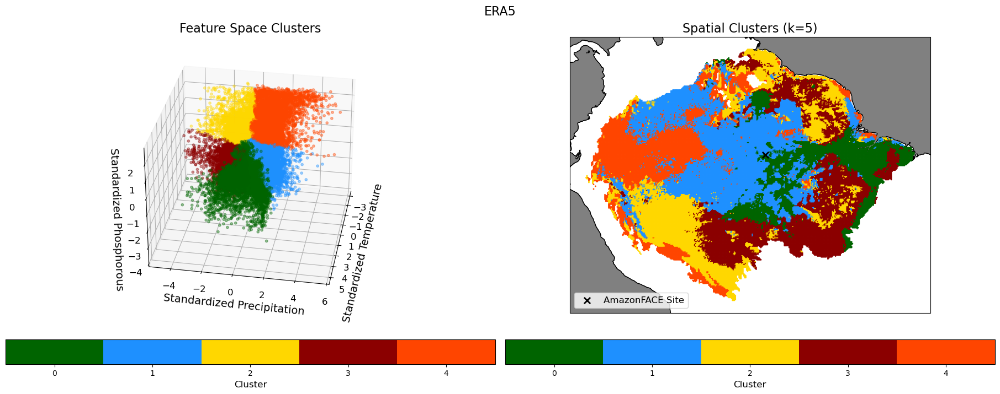

Cluster 0: mean distance to centroid = 2.402, std = 1.159
Cluster 1: mean distance to centroid = 1.830, std = 0.684
Cluster 2: mean distance to centroid = 1.955, std = 0.894
Cluster 3: mean distance to centroid = 1.863, std = 0.900
Cluster 4: mean distance to centroid = 2.473, std = 1.185


In [4]:
era_kmeans, era_kmeans_labels, era_n, era_dist_to_centroids = kmeans_clustering_fit(df_era_trans, n=5)
plot_clusters(df_era_trans, era_kmeans_labels, shared_plot=False, title = "ERA5")
#for each cluster print dist_to_centroids mean and std
for i in range(era_n):
    print(f"Cluster {i}: mean distance to centroid = {era_dist_to_centroids[era_kmeans_labels == i].mean():.3f}, std = {era_dist_to_centroids[era_kmeans_labels == i].std(ddof=1):.3f}")

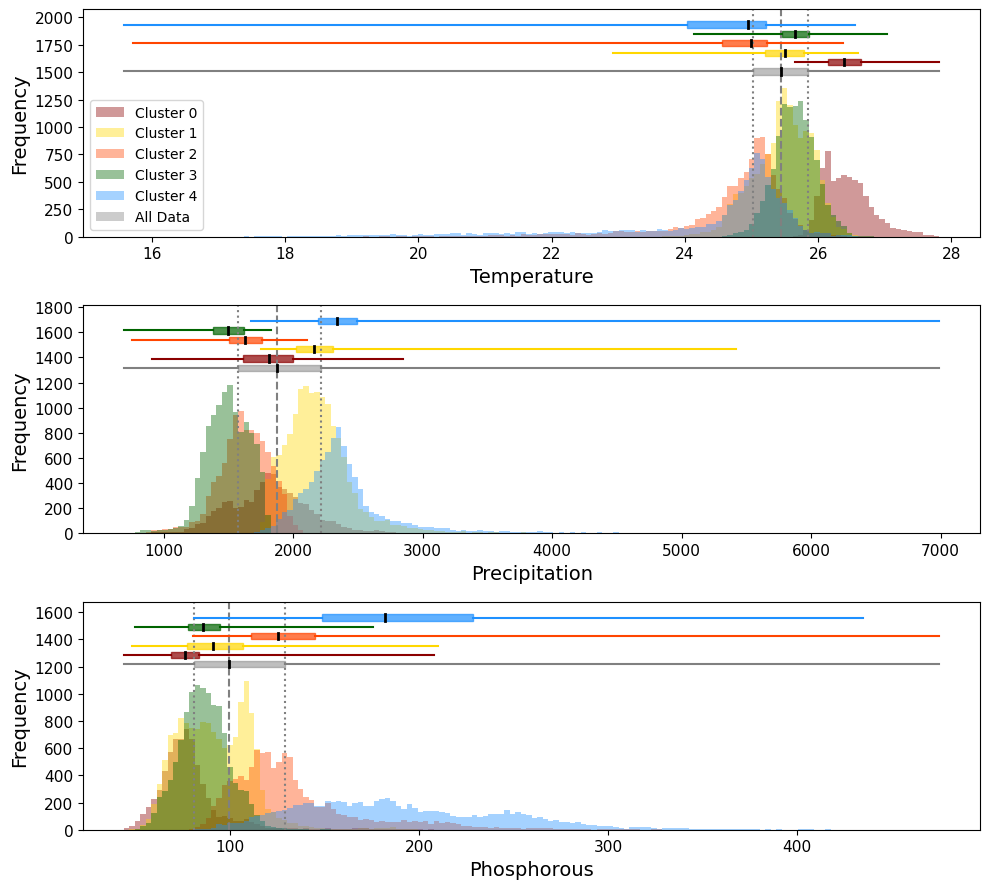

In [5]:
plot_marg_dist_new(df_era, era_kmeans_labels, era_n)


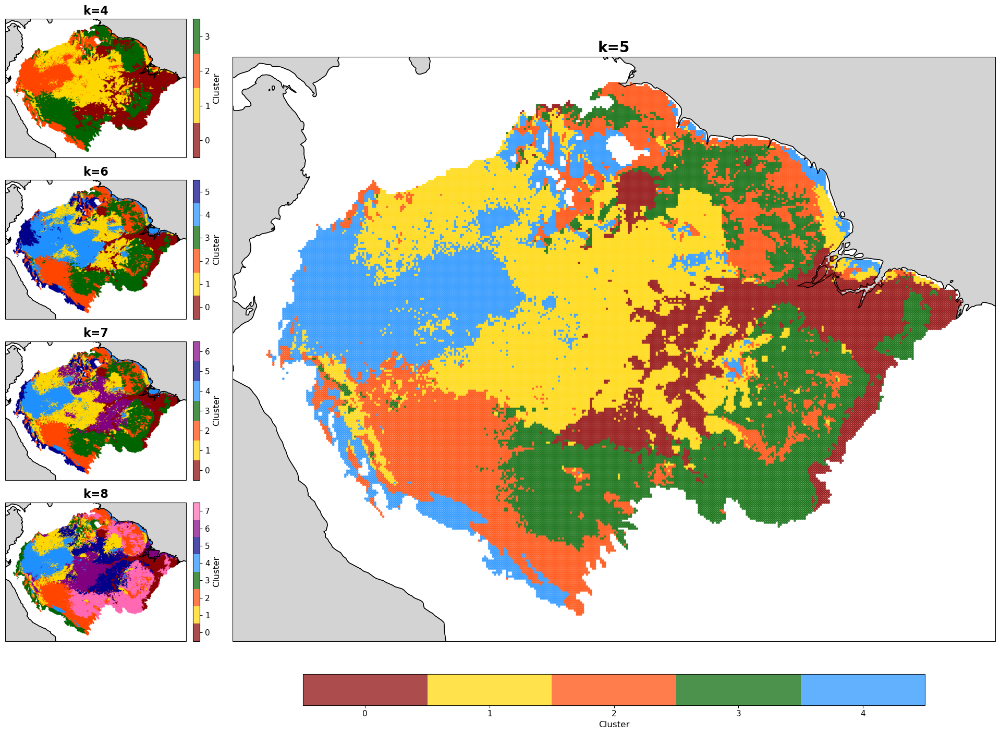

({4: KMeans(n_clusters=4, random_state=42),
  5: KMeans(n_clusters=5, random_state=42),
  6: KMeans(n_clusters=6, random_state=42),
  7: KMeans(n_clusters=7, random_state=42),
  8: KMeans(random_state=42)},
 {4: array([3, 3, 3, ..., 3, 3, 3], shape=(52915,), dtype=int32),
  5: array([2, 2, 2, ..., 2, 2, 2], shape=(52915,), dtype=int32),
  6: array([2, 2, 2, ..., 2, 2, 2], shape=(52915,), dtype=int32),
  7: array([2, 2, 2, ..., 2, 2, 2], shape=(52915,), dtype=int32),
  8: array([2, 2, 2, ..., 2, 2, 2], shape=(52915,), dtype=int32)})

In [6]:
plot_cluster_maps_multi_k(df_era_trans, random_state=42, point_size=1)

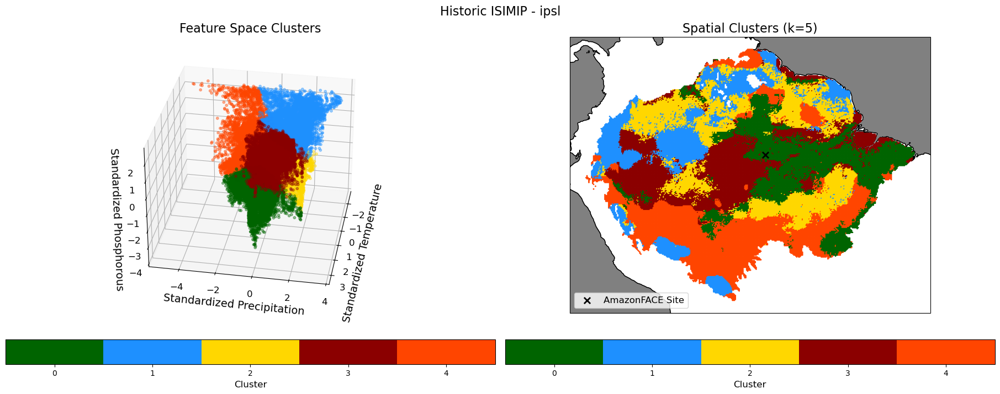

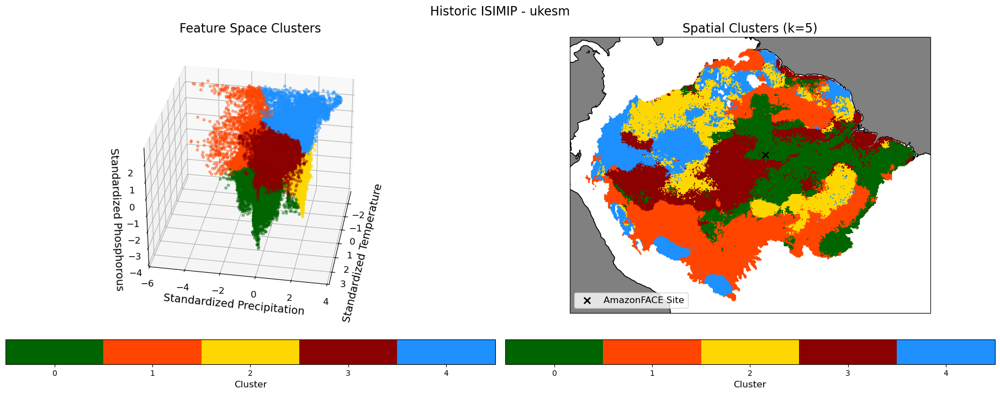

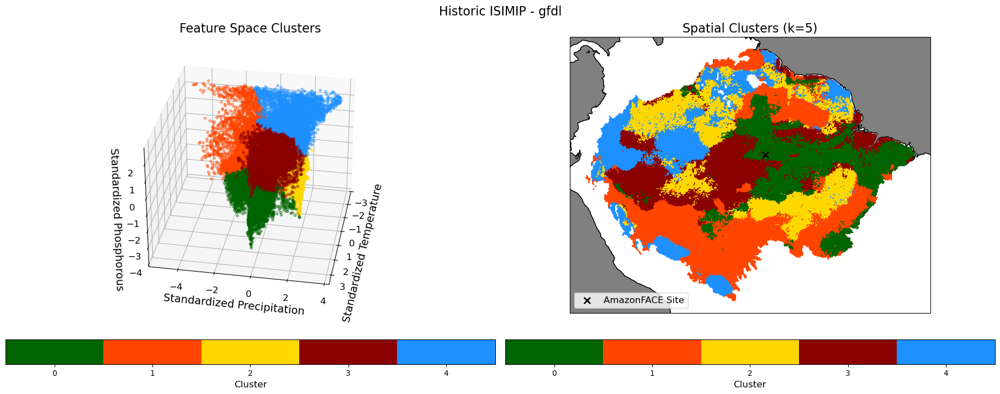

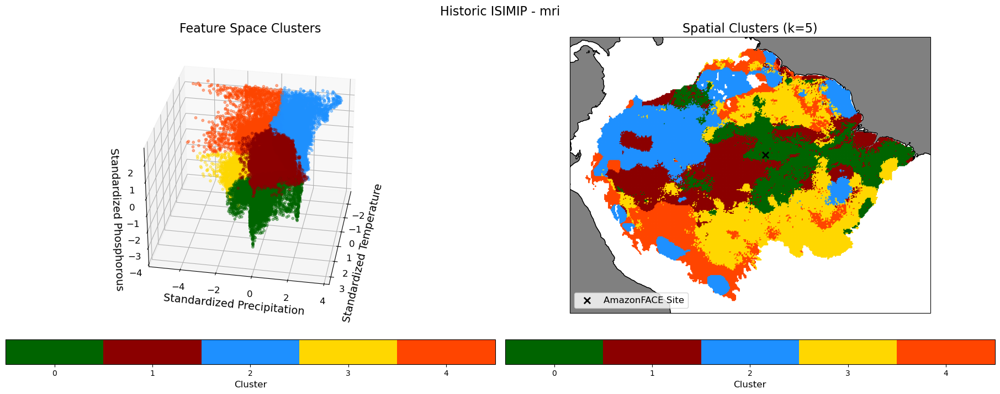

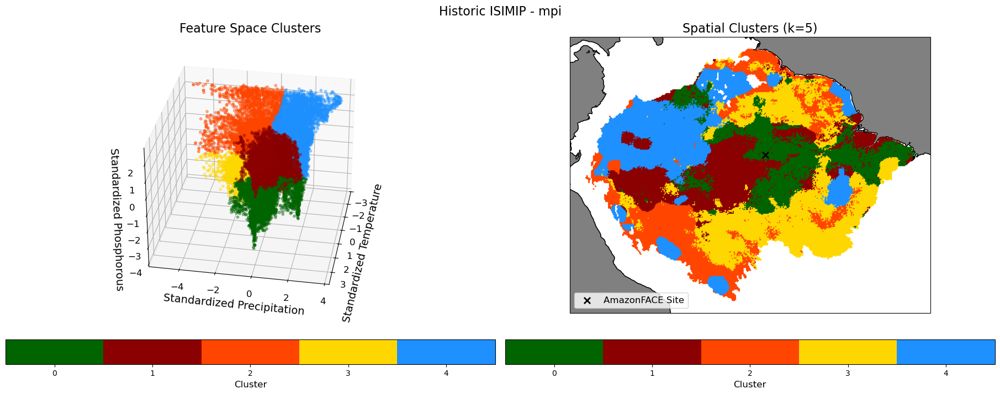

In [18]:
for m in ["ipsl", "ukesm", "gfdl", "mri", "mpi"]:
    model_df = globals()[f"df_{m}"]
    model_df_trans = globals()[f"df_trans_{m}"]

    driving_kmeans, driving_labels, driving_n, driving_dist_to_centroids = kmeans_clustering_fit(model_df_trans, n=5)
    globals()[f"{m}_driving_labels"] = driving_labels
    plot_clusters(model_df_trans, driving_labels, title = f"Historic ISIMIP - {m}", shared_plot=False, model = m)


In [19]:
#loop through each driving labels and renumber them (ipsl stays) (ukesm 4->1, 1->4) (gfdl 4->1, 1->4) (mri 4->1, 1->4) (mpi 2->1, 3->2, 1->3) (mpi 4->1, 3->2, 1_3, 2->4)
for m in ["ukesm", "gfdl", "mri", "mpi"]:
    driving_labels = globals()[f"{m}_driving_labels"]
    if m == "ukesm":
        # Reorder: 4->1, 1->4
        new_order = {0: 0, 1: 4, 2: 2, 3: 3, 4: 1}
    elif m == "gfdl":
        # Reorder: 4->1, 1->4
        new_order = {0: 0, 1: 4, 2: 2, 3: 3, 4: 1}
    elif m == "mri":
        # Reorder: 4->1, 1->4
        new_order = {0: 0, 1: 3, 2: 1, 3: 2, 4: 4}
    elif m == "mpi":
        # Reorder: 2->1, 3->2, 1->3, and then adjust for the last one
        new_order = {0: 0, 1: 3, 2: 4, 3: 2, 4: 1}

    reordered_labels = np.vectorize(new_order.get)(driving_labels)
    globals()[f"{m}_driving_labels"] = reordered_labels

# plot spatial 5 subplots for each driving model, with the number 1 cluster in blue and all others in grey
# fig, axes = plt.subplots(1, 5, figsize=(20, 4), constrained_layout=True, subplot_kw={'projection': ccrs.PlateCarree()})
# for idx, m in enumerate(["ipsl", "ukesm", "gfdl", "mri", "mpi"]):
#     model_df = globals()[f"df_{m}"]
#     driving_labels = globals()[f"{m}_driving_labels"]
#     axes[idx].scatter(
#         model_df['Longitude'], model_df['Latitude'],
#         c=np.where(driving_labels == 3, 'darkred', 'lightgrey'),
#         s=1,
#         alpha=0.7,
#         transform=ccrs.PlateCarree()
#     )
#     axes[idx].coastlines()
#     axes[idx].add_feature(cfeature.OCEAN, zorder=-1, edgecolor='black', facecolor='lightgrey')
#     axes[idx].set_title(f"{m.upper()} Driving Model", fontsize=14)
# plt.suptitle("Spatial Distribution of Cluster 3 (red) vs Others (Grey)", fontsize=16)
# plt.show()

IPSL appears in consensus models: 95.87% of the time (excluding 'No Consensus')
UKESM appears in consensus models: 92.44% of the time (excluding 'No Consensus')
GFDL appears in consensus models: 94.31% of the time (excluding 'No Consensus')
MRI appears in consensus models: 70.34% of the time (excluding 'No Consensus')
MPI appears in consensus models: 67.79% of the time (excluding 'No Consensus')


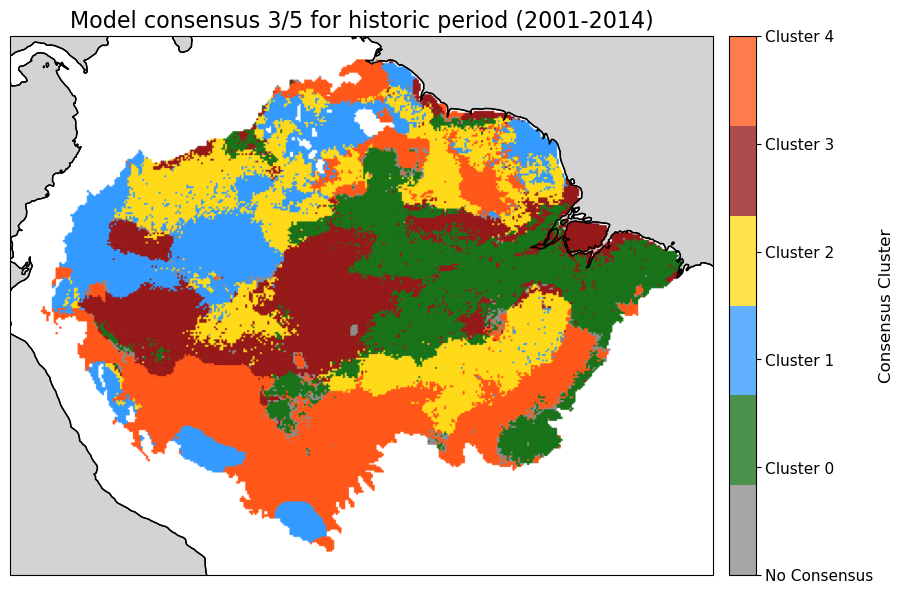

In [30]:
cluster_df = pd.DataFrame({
    'ipsl': globals()['ipsl_driving_labels'],
    'ukesm': globals()['ukesm_driving_labels'],
    'gfdl': globals()['gfdl_driving_labels'],
    'mri': globals()['mri_driving_labels'],
    'mpi': globals()['mpi_driving_labels']
})

q=3

cluster_df['consensus'] = cluster_df.apply(
    lambda row: row.value_counts().index[0]
    if row.value_counts().iloc[0] >= q else -1,
    axis=1
)


#add a column which lists the names of the 3+ models which agree on the consensus cluster, or "No Consensus" if there is no consensus
cluster_df['consensus_models'] = cluster_df.apply(
    lambda row: ', '.join(row.index[row == row.value_counts().index[0]].tolist())
    if row.value_counts().iloc[0] >= q else 'No Consensus',
    axis=1
)

#print out the percentage that each model name appears in the consensus_models column, excluding "No Consensus"
for m in ["ipsl", "ukesm", "gfdl", "mri", "mpi"]:
    count = cluster_df['consensus_models'].str.contains(m).sum()
    total = len(cluster_df) - (cluster_df['consensus_models'] == 'No Consensus').sum()
    percentage = (count / total) * 100 if total > 0 else 0
    print(f"{m.upper()} appears in consensus models: {percentage:.2f}% of the time (excluding 'No Consensus')")



# cluster_df['consensus'] = cluster_df.apply(lambda row: row[0] if (row == row[0]).all() else -1, axis=1)

#spatial plot of cluster_df coloring by consensus column, with -1 in grey and 0-4 in the same colors as before
cmap_consensus = plt.cm.colors.ListedColormap(['grey', 'darkgreen', 'dodgerblue', 'gold', 'darkred', 'orangered'])
fig, ax = plt.subplots(figsize=(10, 7), subplot_kw={'projection': ccrs.PlateCarree()})
scatter = ax.scatter(
    df_ipsl['Longitude'], df_ipsl['Latitude'],
    c=cluster_df['consensus'],
    cmap=cmap_consensus,
    vmin=-1, vmax=4,
    s=1,
    alpha=0.7,
    transform=ccrs.PlateCarree()
)
ax.coastlines()
ax.add_feature(cfeature.OCEAN, zorder=-1, edgecolor='black', facecolor='lightgrey')
ax.set_title("Model consensus 3/5 for historic period (2001-2014)", fontsize=16)
cbar = fig.colorbar(scatter, ax=ax, orientation='vertical', fraction=0.046, pad=0.02)
cbar.set_ticks([-1, 0, 1, 2, 3, 4])
cbar.set_ticklabels(['No Consensus', 'Cluster 0', 'Cluster 1', 'Cluster 2', 'Cluster 3', 'Cluster 4'])
cbar.set_label('Consensus Cluster', fontsize=12)
cbar.ax.tick_params(labelsize=11)
plt.show()

In [31]:
#print percentage of points that have consensus (i.e., consensus != -1)
consensus_count = (cluster_df['consensus'] != -1).sum()
total_count = len(cluster_df)
consensus_percentage = (consensus_count / total_count) * 100
print(f"Percentage of points with consensus (3/5): {consensus_percentage:.2f}%")

Percentage of points with consensus (3/5): 98.02%


In [32]:
model_sets = [
    ['ipsl', 'ukesm', 'gfdl'],
    ['ipsl', 'ukesm', 'mri'],
    ['ipsl', 'ukesm', 'mpi'],
    ['ipsl', 'gfdl', 'mri'],
    ['ipsl', 'gfdl', 'mpi'],
    ['ipsl', 'mri', 'mpi'],
    ['ukesm', 'gfdl', 'mri'],
    ['ukesm', 'gfdl', 'mpi'],
    ['ukesm', 'mri', 'mpi'],
    ['gfdl', 'mri', 'mpi']

]

for models in model_sets:
    agreement_mask = cluster_df[models].nunique(axis=1).eq(1)

    # % of all points
    percentage_all = agreement_mask.mean() * 100

    # % of consensus (non-grey) points only
    consensus_mask = cluster_df['consensus'] != -1
    percentage_consensus = (
        agreement_mask[consensus_mask].mean() * 100
        if consensus_mask.any() else 0.0
    )

    model_names = ', '.join(m.upper() for m in models)
    print(f"{model_names} agreement (all points): {percentage_all:.2f}%")
    print(f"{model_names} agreement (consensus / non-grey points): {percentage_consensus:.2f}%")

IPSL, UKESM, GFDL agreement (all points): 86.16%
IPSL, UKESM, GFDL agreement (consensus / non-grey points): 87.89%
IPSL, UKESM, MRI agreement (all points): 58.54%
IPSL, UKESM, MRI agreement (consensus / non-grey points): 59.72%
IPSL, UKESM, MPI agreement (all points): 56.42%
IPSL, UKESM, MPI agreement (consensus / non-grey points): 57.56%
IPSL, GFDL, MRI agreement (all points): 61.11%
IPSL, GFDL, MRI agreement (consensus / non-grey points): 62.34%
IPSL, GFDL, MPI agreement (all points): 58.42%
IPSL, GFDL, MPI agreement (consensus / non-grey points): 59.60%
IPSL, MRI, MPI agreement (all points): 61.00%
IPSL, MRI, MPI agreement (consensus / non-grey points): 62.23%
UKESM, GFDL, MRI agreement (all points): 59.56%
UKESM, GFDL, MRI agreement (consensus / non-grey points): 60.76%
UKESM, GFDL, MPI agreement (all points): 57.35%
UKESM, GFDL, MPI agreement (consensus / non-grey points): 58.51%
UKESM, MRI, MPI agreement (all points): 58.03%
UKESM, MRI, MPI agreement (consensus / non-grey points)

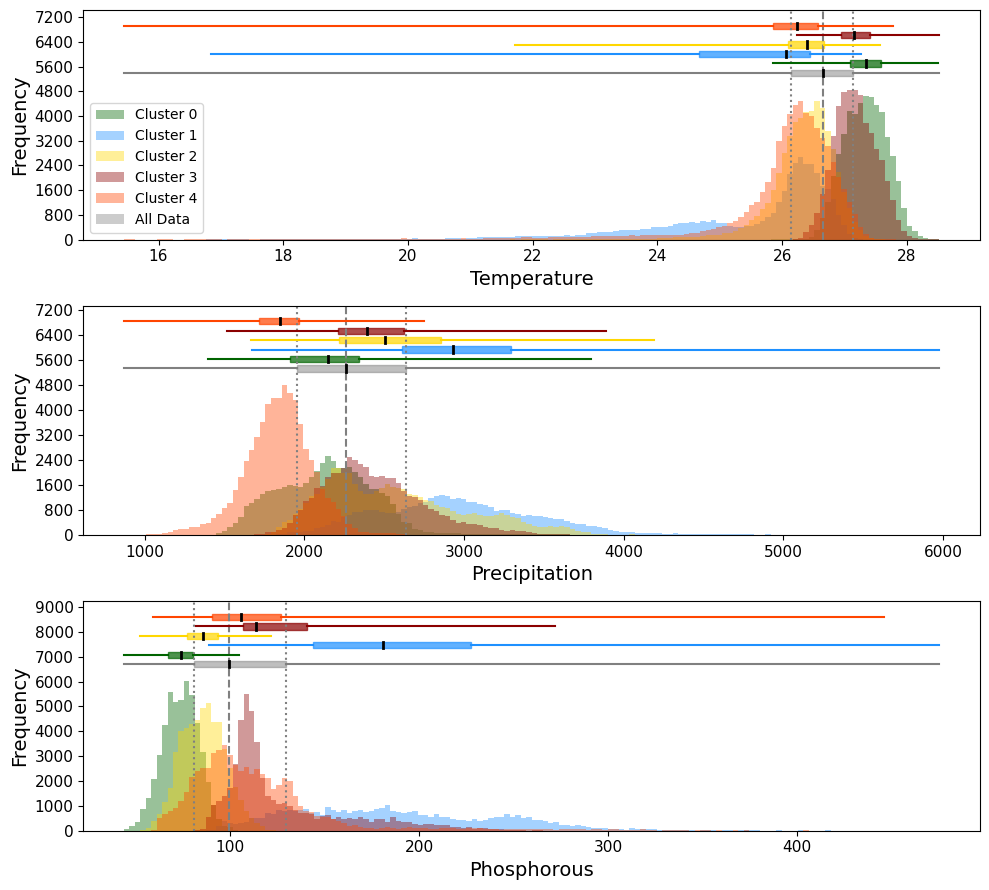

In [43]:
# make a df which is temp, precip and phosphouros, and the consensus cluster, for the ipsl, ukesm, gfld, mri and mpi data flattened and concatenated
combined_df = pd.DataFrame({
    'Temperature': pd.concat([df_ipsl['Temperature'], df_ukesm['Temperature'], df_gfdl['Temperature'], df_mri['Temperature'], df_mpi['Temperature']], ignore_index=True),
    'Precipitation': pd.concat([df_ipsl['Precipitation'], df_ukesm['Precipitation'], df_gfdl['Precipitation'], df_mri['Precipitation'], df_mpi['Precipitation']], ignore_index=True),
    'Phosphorous': pd.concat([df_ipsl['Phosphorous'], df_ukesm['Phosphorous'], df_gfdl['Phosphorous'], df_mri['Phosphorous'], df_mpi['Phosphorous']], ignore_index=True),
    'Consensus Cluster': pd.concat([cluster_df['consensus'], cluster_df['consensus'], cluster_df['consensus'], cluster_df['consensus'], cluster_df['consensus']], ignore_index=True)
})

#remove rows with no consensus
combined_df = combined_df[combined_df['Consensus Cluster'] != -1]

labels = combined_df['Consensus Cluster'].values

#removes the consensus cluster column from the df
combined_df = combined_df.drop(columns=['Consensus Cluster'])

plot_marg_dist_new(combined_df, labels, 5, combined = True)


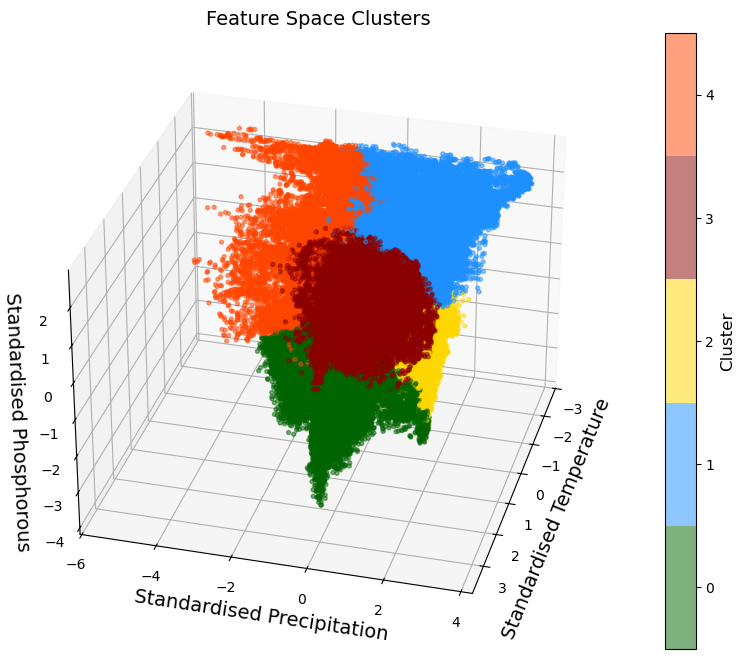

In [89]:
# Create a combined dataframe with transformed data and consensus labels (where the data is stnadardized)
combined_trans_df = pd.DataFrame({
    'Temperature': pd.concat([df_trans_ipsl['Temperature'], df_trans_ukesm['Temperature'], df_trans_gfdl['Temperature'], df_trans_mri['Temperature'], df_trans_mpi['Temperature']], ignore_index=True),
    'Precipitation': pd.concat([df_trans_ipsl['Precipitation'], df_trans_ukesm['Precipitation'], df_trans_gfdl['Precipitation'], df_trans_mri['Precipitation'], df_trans_mpi['Precipitation']], ignore_index=True),
    'Phosphorous': pd.concat([df_trans_ipsl['Phosphorous'], df_trans_ukesm['Phosphorous'], df_trans_gfdl['Phosphorous'], df_trans_mri['Phosphorous'], df_trans_mpi['Phosphorous']], ignore_index=True),
    'consensus': pd.concat([cluster_df['consensus'], cluster_df['consensus'], cluster_df['consensus'], cluster_df['consensus'], cluster_df['consensus']], ignore_index=True)
})  

#plot the 3D feature space of the combined transformed data with the consensus cluster labels
combined_feature_space_plot(combined_trans_df[combined_trans_df['consensus'] != -1])  # Ex


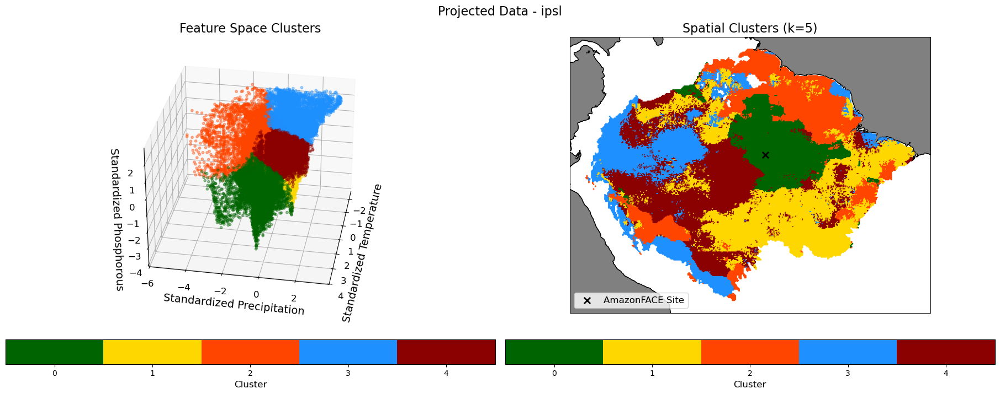

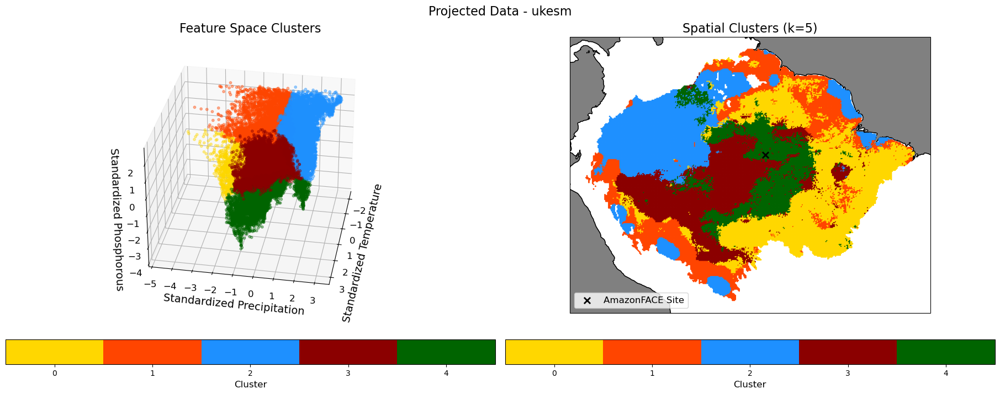

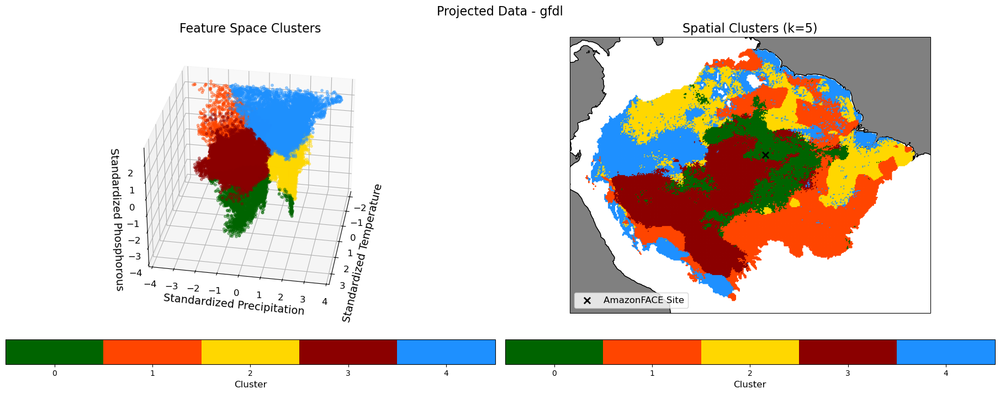

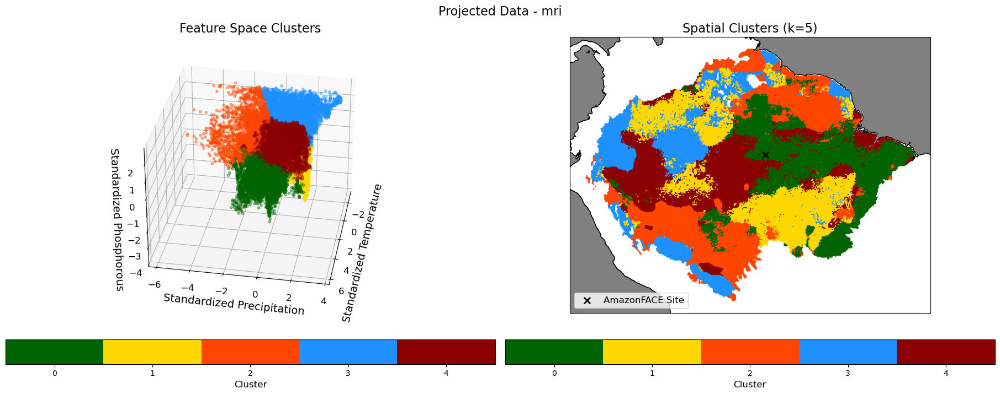

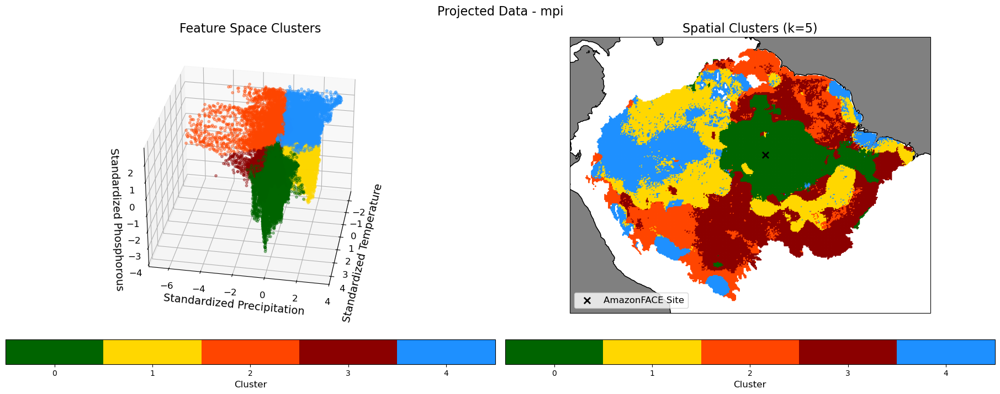

In [34]:
#true restan

for m in ["ipsl", "ukesm", "gfdl", "mri", "mpi"]:
    model_df_trans = globals()[f"df_trans_{m}"]
    model_df_proj = globals()[f"df_proj_trans_{m}"]

    proj_kmeans, proj_labels, proj_n, proj_dist_to_centroids = kmeans_clustering_fit(model_df_proj, n=5)
    #save the proj_labels to a global variable
    globals()[f"{m}_proj_labels"] = proj_labels
    plot_clusters(model_df_proj, proj_labels, shared_plot=False, title = f"Projected Data - {m}", restan = True, model = m)

In [35]:
#loop through each projected labels and renumber them (ipsl stays) (ukesm 4->1, 1->4) (gfdl 4->1, 1->4) (mri 4->1, 1->4) (mpi 2->1, 3->2, 1->3) (mpi 4->1, 3->2, 1_3, 2->4)
for m in ["ukesm", "gfdl", "mri", "mpi"]:
    projected_labels = globals()[f"{m}_proj_labels"]
    if m == "ukesm":
        new_order = {0: 1, 1: 2, 2: 3, 3: 4, 4: 0}
    elif m == "gfdl":
        new_order = {0: 0, 1: 2, 2: 1, 3: 4, 4: 3}
    elif m == "mri":
        new_order = {0: 0, 1: 1, 2: 2, 3: 3, 4: 4}
    elif m == "mpi":
        new_order = {0: 0, 1: 1, 2: 2, 3: 4, 4: 3}

    reordered_labels = np.vectorize(new_order.get)(projected_labels)
    globals()[f"{m}_proj_labels"] = reordered_labels

IPSL appears in consensus models: 85.41% of the time (excluding 'No Consensus')
UKESM appears in consensus models: 76.82% of the time (excluding 'No Consensus')
GFDL appears in consensus models: 77.92% of the time (excluding 'No Consensus')
MRI appears in consensus models: 82.20% of the time (excluding 'No Consensus')
MPI appears in consensus models: 68.01% of the time (excluding 'No Consensus')


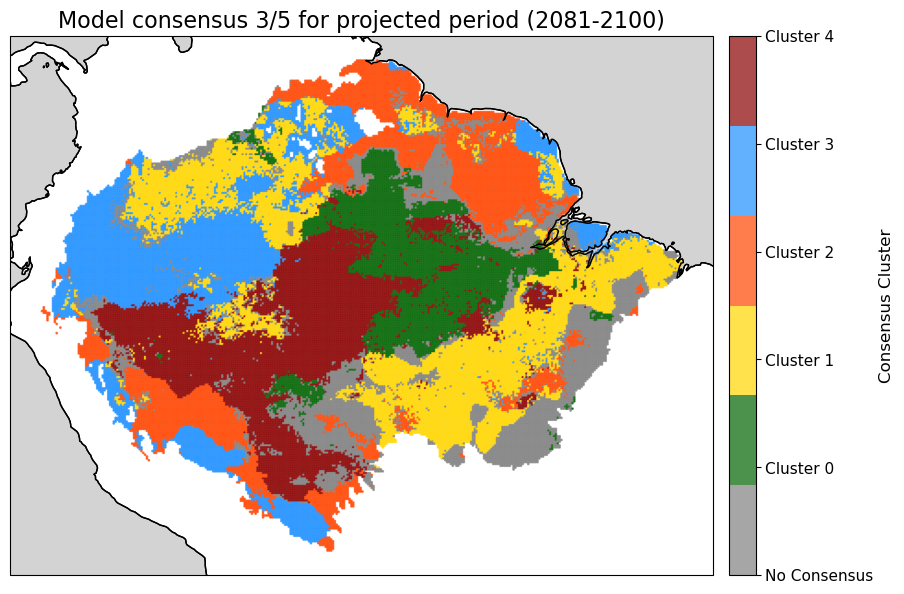

In [36]:
cluster_proj_df = pd.DataFrame({
    'ipsl': globals()['ipsl_proj_labels'],
    'ukesm': globals()['ukesm_proj_labels'],
    'gfdl': globals()['gfdl_proj_labels'],
    'mri': globals()['mri_proj_labels'],
    'mpi': globals()['mpi_proj_labels']
})

q=3

cluster_proj_df['consensus'] = cluster_proj_df.apply(
    lambda row: row.value_counts().index[0]
    if row.value_counts().iloc[0] >= q else -1,
    axis=1
)

#add a column which lists the names of the 3+ models which agree on the consensus cluster, or "No Consensus" if there is no consensus
cluster_proj_df['consensus_models'] = cluster_proj_df.apply(
    lambda row: ', '.join(row.index[row == row.value_counts().index[0]].tolist())
    if row.value_counts().iloc[0] >= q else 'No Consensus',
    axis=1
)

#print out the percentage that each model name appears in the consensus_models column, excluding "No Consensus"
for m in ["ipsl", "ukesm", "gfdl", "mri", "mpi"]:
    count = cluster_proj_df['consensus_models'].str.contains(m).sum()
    total = len(cluster_proj_df) - (cluster_proj_df['consensus_models'] == 'No Consensus').sum()
    percentage = (count / total) * 100 if total > 0 else 0
    print(f"{m.upper()} appears in consensus models: {percentage:.2f}% of the time (excluding 'No Consensus')")



# cluster_df['consensus'] = cluster_df.apply(lambda row: row[0] if (row == row[0]).all() else -1, axis=1)

#spatial plot of cluster_df coloring by consensus column, with -1 in grey and 0-4 in the same colors as before
cmap_consensus = plt.cm.colors.ListedColormap(['grey', 'darkgreen', 'gold', 'orangered', 'dodgerblue', 'darkred'])
fig, ax = plt.subplots(figsize=(10, 7), subplot_kw={'projection': ccrs.PlateCarree()})
scatter = ax.scatter(
    df_ipsl['Longitude'], df_ipsl['Latitude'],
    c=cluster_proj_df['consensus'],
    cmap=cmap_consensus,
    vmin=-1, vmax=4,
    s=1,
    alpha=0.7,
    transform=ccrs.PlateCarree()
)
ax.coastlines()
ax.add_feature(cfeature.OCEAN, zorder=-1, edgecolor='black', facecolor='lightgrey')
ax.set_title("Model consensus 3/5 for projected period (2081-2100)", fontsize=16)
cbar = fig.colorbar(scatter, ax=ax, orientation='vertical', fraction=0.046, pad=0.02)
cbar.set_ticks([-1, 0, 1, 2, 3, 4])
cbar.set_ticklabels(['No Consensus', 'Cluster 0', 'Cluster 1', 'Cluster 2', 'Cluster 3', 'Cluster 4'])
cbar.set_label('Consensus Cluster', fontsize=12)
cbar.ax.tick_params(labelsize=11)
plt.show()

In [37]:
model_sets = [
    ['ipsl', 'ukesm', 'gfdl'],
    ['ipsl', 'ukesm', 'mri'],
    ['ipsl', 'ukesm', 'mpi'],
    ['ipsl', 'gfdl', 'mri'],
    ['ipsl', 'gfdl', 'mpi'],
    ['ipsl', 'mri', 'mpi'],
    ['ukesm', 'gfdl', 'mri'],
    ['ukesm', 'gfdl', 'mpi'],
    ['ukesm', 'mri', 'mpi'],
    ['gfdl', 'mri', 'mpi']

]

for models in model_sets:
    agreement = cluster_proj_df[models].nunique(axis=1).eq(1).sum()
    percentage = agreement / len(cluster_proj_df) * 100
    print(f"Percentage of points with {', '.join(m.upper() for m in models)} in agreement: {percentage:.2f}%")

Percentage of points with IPSL, UKESM, GFDL in agreement: 43.62%
Percentage of points with IPSL, UKESM, MRI in agreement: 44.81%
Percentage of points with IPSL, UKESM, MPI in agreement: 35.81%
Percentage of points with IPSL, GFDL, MRI in agreement: 43.35%
Percentage of points with IPSL, GFDL, MPI in agreement: 36.00%
Percentage of points with IPSL, MRI, MPI in agreement: 40.72%
Percentage of points with UKESM, GFDL, MRI in agreement: 38.12%
Percentage of points with UKESM, GFDL, MPI in agreement: 33.12%
Percentage of points with UKESM, MRI, MPI in agreement: 32.18%
Percentage of points with GFDL, MRI, MPI in agreement: 35.77%


In [38]:
#print what percentage of the input points which have consensus (i.e., consensus != -1)
consensus_count_proj = (cluster_proj_df['consensus'] != -1).sum()
total_count_proj = len(cluster_proj_df)
consensus_percentage_proj = (consensus_count_proj / total_count_proj) * 100
print(f"Percentage of points with consensus (3/5) in projected data: {consensus_percentage_proj:.2f}%") 

Percentage of points with consensus (3/5) in projected data: 83.76%


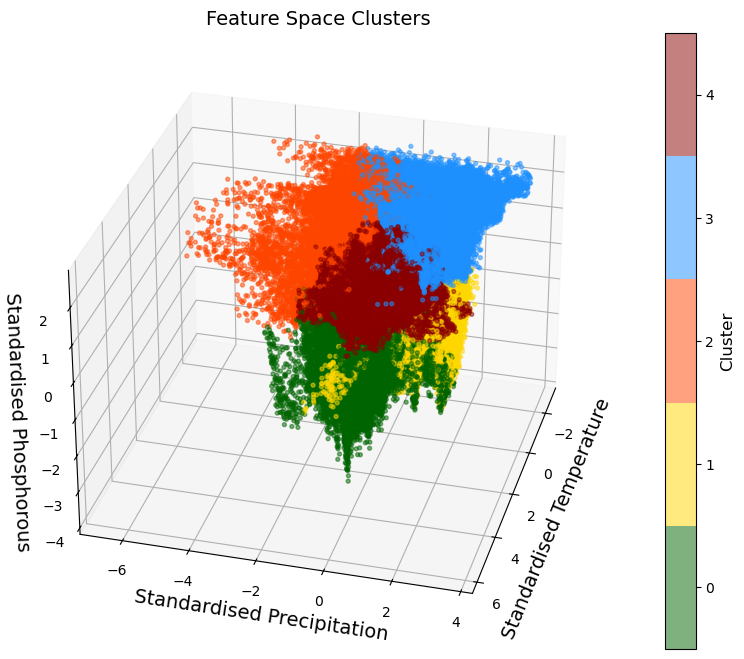

In [92]:
# Create a combined dataframe with transformed data and consensus labels (where the data is stnadardized)
combined_proj_trans_df = pd.DataFrame({
    'Temperature': pd.concat([df_proj_trans_ipsl['Temperature'], df_proj_trans_ukesm['Temperature'], df_proj_trans_gfdl['Temperature'], df_proj_trans_mri['Temperature'], df_proj_trans_mpi['Temperature']], ignore_index=True),
    'Precipitation': pd.concat([df_proj_trans_ipsl['Precipitation'], df_proj_trans_ukesm['Precipitation'], df_proj_trans_gfdl['Precipitation'], df_proj_trans_mri['Precipitation'], df_proj_trans_mpi['Precipitation']], ignore_index=True),
    'Phosphorous': pd.concat([df_proj_trans_ipsl['Phosphorous'], df_proj_trans_ukesm['Phosphorous'], df_proj_trans_gfdl['Phosphorous'], df_proj_trans_mri['Phosphorous'], df_proj_trans_mpi['Phosphorous']], ignore_index=True),
    'consensus': pd.concat([cluster_proj_df['consensus'], cluster_proj_df['consensus'], cluster_proj_df['consensus'], cluster_proj_df['consensus'], cluster_proj_df['consensus']], ignore_index=True)
})  

combined_feature_space_plot(combined_proj_trans_df[combined_proj_trans_df['consensus'] != -1], proj = True)  # Exclude points with no consensus for plotting


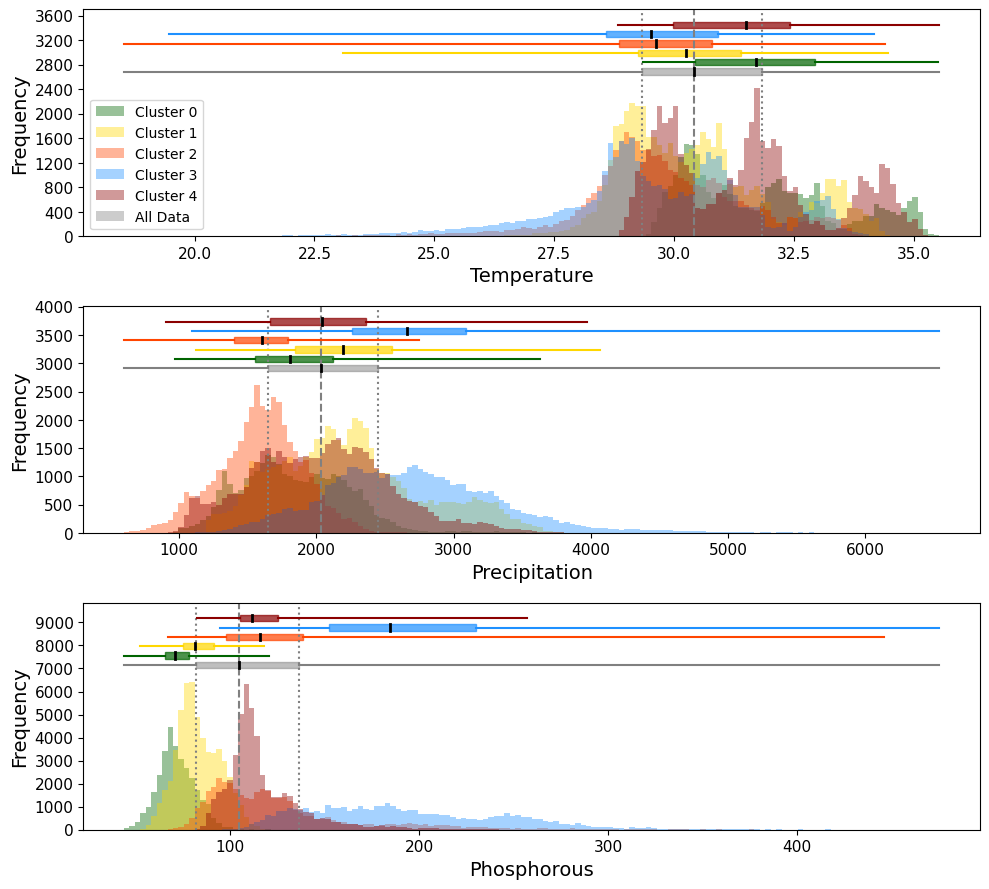

In [39]:


proj_labels = combined_proj_df['Consensus Cluster'].values

#removes the consensus cluster column from the df
combined_proj_df = combined_proj_df.drop(columns=['Consensus Cluster'])

plot_marg_dist_new(combined_proj_df, proj_labels, 5, combined = True, reorder_colors = True)

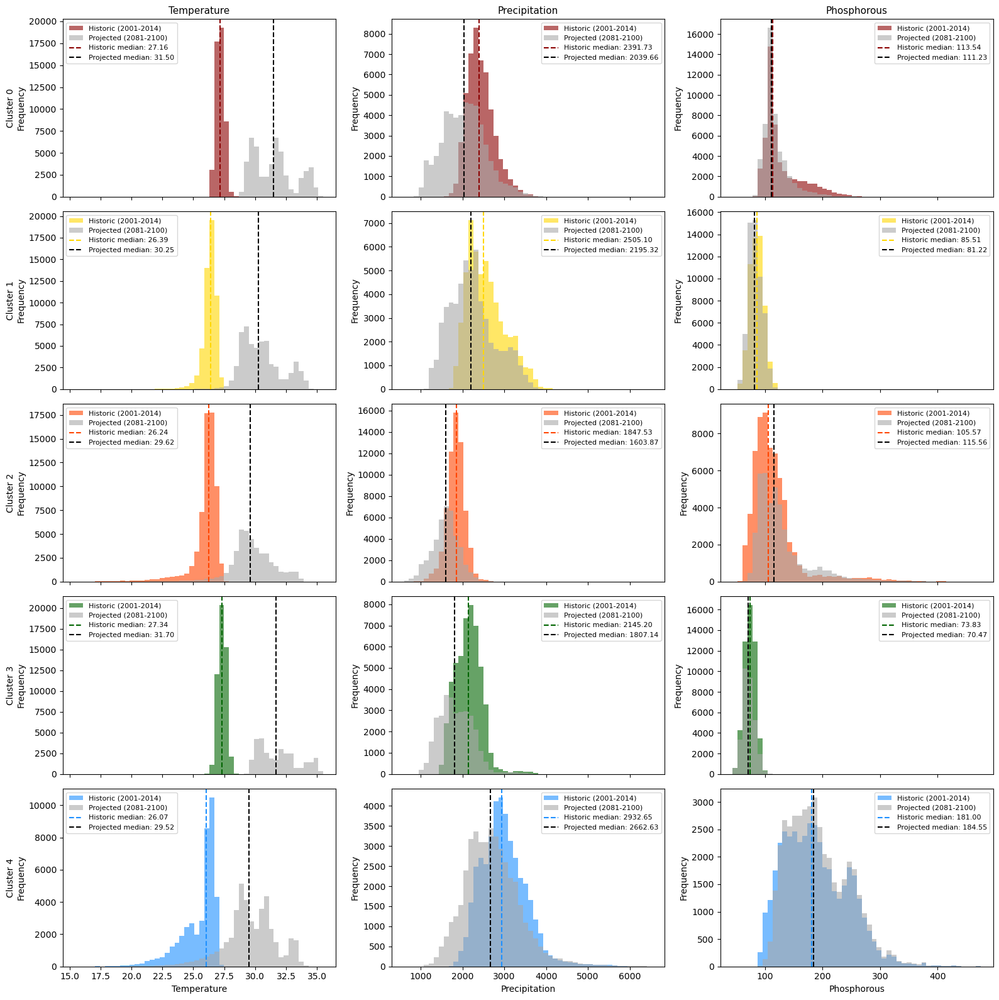

In [102]:
plot_marg_dist_comparison(combined_df, combined_proj_df, labels, proj_labels, 5)

In [30]:
combined_df.head()

,Temperature,Precipitation,Phosphorous
0,26.261928,1420.961590,246.651108
1,26.214005,1475.779165,246.663467
2,26.166081,1530.596741,240.648026
3,26.118157,1585.414317,232.815155
4,26.126328,1647.130948,230.949341


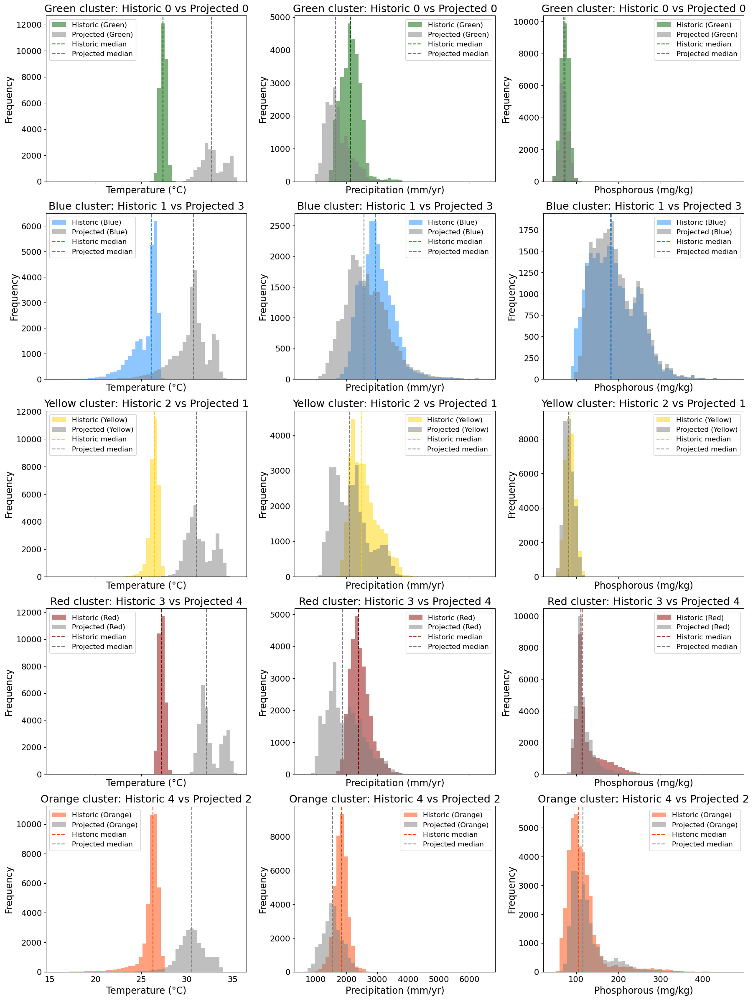

In [31]:
# Validate expected columns before plotting
features = ['Temperature', 'Precipitation', 'Phosphorous']
units = ['°C', 'mm/yr', 'mg/kg']

for name, d in [('combined_df', combined_df), ('combined_proj_df', combined_proj_df)]:
    missing = [c for c in features if c not in d.columns]
    if missing:
        raise KeyError(f"{name} is missing columns: {missing}. Available: {list(d.columns)}")

fig, axes = plt.subplots(5, 3, figsize=(18, 24), sharex='col')

# Larger text settings
label_fs = 16
title_fs = 18
tick_fs = 14
legend_fs = 12

# Shared bins per feature
feature_bins = {}
for feature in features:
    feat_min = min(combined_df[feature].min(), combined_proj_df[feature].min())
    feat_max = max(combined_df[feature].max(), combined_proj_df[feature].max())
    feature_bins[feature] = np.linspace(feat_min, feat_max, 51)

# Match clusters by colour between historic and projected label schemes
hist_to_proj = {0: 0, 1: 3, 2: 1, 3: 4, 4: 2}
cluster_colors = {0: 'darkgreen', 1: 'dodgerblue', 2: 'gold', 3: 'darkred', 4: 'orangered'}
cluster_names = {0: 'Green', 1: 'Blue', 2: 'Yellow', 3: 'Red', 4: 'Orange'}

for row, hist_cluster in enumerate(range(5)):
    proj_cluster = hist_to_proj[hist_cluster]
    color = cluster_colors[hist_cluster]
    cname = cluster_names[hist_cluster]

    for col, (feature, unit) in enumerate(zip(features, units)):
        ax = axes[row, col]

        hist_data = combined_df.loc[labels == hist_cluster, feature]
        proj_data = combined_proj_df.loc[proj_labels == proj_cluster, feature]
        bin_edges = feature_bins[feature]

        ax.hist(hist_data, bins=bin_edges, alpha=0.5, color=color, label=f'Historic ({cname})')
        ax.hist(proj_data, bins=bin_edges, alpha=0.5, color='grey', label=f'Projected ({cname})')

        if len(hist_data) > 0:
            ax.axvline(hist_data.median(), color=color, linestyle='--', linewidth=1.5, label='Historic median')
        if len(proj_data) > 0:
            ax.axvline(proj_data.median(), color='grey', linestyle='--', linewidth=1.5, label='Projected median')

        ax.set_xlabel(f'{feature} ({unit})', fontsize=label_fs)
        ax.set_ylabel('Frequency', fontsize=label_fs)
        ax.set_title(f'{cname} cluster: Historic {hist_cluster} vs Projected {proj_cluster}', fontsize=title_fs)
        ax.tick_params(labelsize=tick_fs)
        ax.legend(fontsize=legend_fs)

plt.tight_layout()
plt.show()


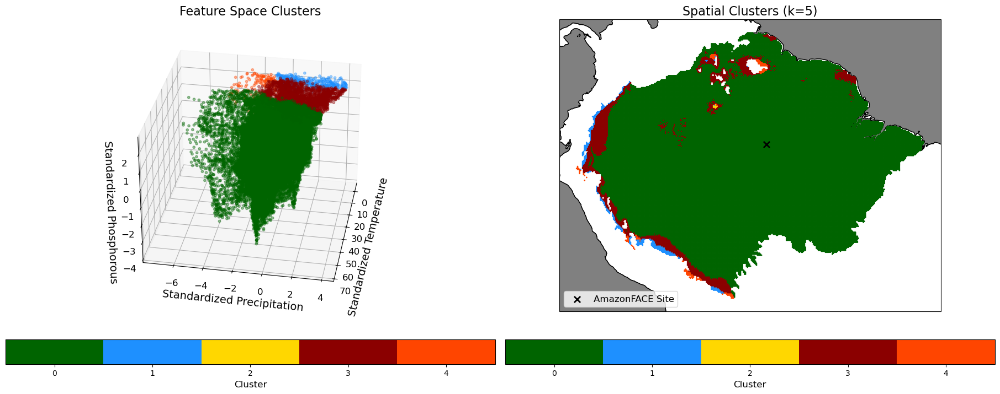

Cluster 0: mean distance to centroid = 25.183, std = 11.149
Cluster 1: mean distance to centroid = 3.070, std = 1.116
Cluster 2: mean distance to centroid = 1.501, std = 0.506
Cluster 3: mean distance to centroid = 7.488, std = 4.080
Cluster 4: mean distance to centroid = 3.062, std = 1.158


In [ ]:
proj_labels, proj_n, proj_dist_to_centroids = kmeans_clustering_predict(df_trans, df_proj_trans, 5)
plot_clusters(df_proj_trans, proj_labels, reorder_colors = True, shared_plot=False)
#calculate silhouette score for projected data clusters
# sil_score_proj = silhouette_score(df_proj_trans[['Temperature', 'Precipitation', 'Phosphorous']], proj_labels)
# print(f'Silhouette Score for projected data clusters: {sil_score_proj:.3f}')    
#for each cluster print dist_to_centroids mean and std
for i in range(proj_n):
    print(f"Cluster {i}: mean distance to centroid = {proj_dist_to_centroids[proj_labels == i].mean():.3f}, std = {proj_dist_to_centroids[proj_labels == i].std(ddof=1):.3f}")

In [ ]:
# hist_dist_to_centroids: array of distances from historic points to centroids
# proj_dist_to_centroids: array of distances from projected points to centroids

results = {}

for k in range(5):
    h = driving_dist_to_centroids[driving_labels == k, k]
    p = proj_dist_to_centroids[proj_labels == k, k]

    # Historical percentiles
    q50 = np.percentile(h, 50)
    q95 = np.percentile(h, 95)
    
    # Novelty rate: projected points above hist 95th percentile
    novelty_rate = np.mean(p > q95)

    # Empirical CDF for p-values
    h_sorted = np.sort(h)
    def emp_pvalue(d):
        # proportion of historical distances <= d
        F = np.searchsorted(h_sorted, d, side='right') / len(h_sorted)
        return 1 - F

    pvals = np.array([emp_pvalue(d) for d in p])
    
    results[k] = {
        "hist_mean": np.mean(h),
        "proj_mean": np.mean(p),
        "hist_95": q95,
        "proj_95": np.percentile(p, 95),
        "novelty_rate": novelty_rate,
        "pval_lt_0.05": np.mean(pvals < 0.05),
        "pval_lt_0.01": np.mean(pvals < 0.01)
    }

results

{0: {'hist_mean': 3.260731702165556,
  'proj_mean': 12.92249241258229,
  'hist_95': 3.837774849004587,
  'proj_95': 13.96013195408395,
  'novelty_rate': 1.0,
  'pval_lt_0.05': 1.0,
  'pval_lt_0.01': 1.0},
 1: {'hist_mean': 3.1302439210157806,
  'proj_mean': 11.846921880193289,
  'hist_95': 3.7511917796029945,
  'proj_95': 12.879987519891635,
  'novelty_rate': 1.0,
  'pval_lt_0.05': 1.0,
  'pval_lt_0.01': 1.0},
 2: {'hist_mean': 2.99332813736108,
  'proj_mean': 10.847251300563872,
  'hist_95': 3.6514467168820453,
  'proj_95': 11.877484385020594,
  'novelty_rate': 1.0,
  'pval_lt_0.05': 1.0,
  'pval_lt_0.01': 1.0},
 3: {'hist_mean': 2.8606992912371885,
  'proj_mean': 9.920877717099376,
  'hist_95': 3.5528389073003703,
  'proj_95': 10.948612247505062,
  'novelty_rate': 1.0,
  'pval_lt_0.05': 1.0,
  'pval_lt_0.01': 1.0},
 4: {'hist_mean': 2.73705707614342,
  'proj_mean': 9.565555775323649,
  'hist_95': 3.459850534871612,
  'proj_95': 10.58528602832143,
  'novelty_rate': 1.0,
  'pval_lt_0.0